# RepSeq UCB Analysis - MIPT seminar

**Как работать с ноутбуком.** Сначала выполняем блок настройки путей и загрузки подготовленных репертуаров, затем разбираем качество данных и отдельные метрики TCR. Код анализирует **β-цепь TCR (TRB)**. Один клоносет соответствует одному образцу, а клонотипу соответствует последовательность рецептора с заданным правилом определения совпадения.

Файлы результатов сохраняются в `outputs/repseq/`; каталог создаётся кодом при выполнении. Предполагается, что данные уже подключены к `data/ucb_figshare/` (например, символьной ссылкой на общую папку с клоносетами и метаданными).

## Imports

**Назначение библиотек.** `pandas` — таблицы и метаданные; `os`/`pathlib` — пути; `repseq.clonosets` — поиск таблиц клонотипов; `repseq.clone_filter` — фильтрация; `repseq.stats` — вычисление метрик; `repseq.plot` — построение графиков; `repseq.beta` — сравнение образцов; `repseq.clustering` — поиск близких последовательностей. `CategoricalDtype` задаёт порядок групп на графиках.

In [1]:
# Импортируем библиотеки, которые потребуются для таблиц, расчёта метрик и графиков.
import pandas as pd
from pandas.api.types import CategoricalDtype
import os

from repseq import clonosets as cl
from repseq import io as repseqio
from repseq import clone_filter as clf
from repseq import stats
from repseq import plot as rsplot
from repseq import clustering
from repseq import beta

**Относительные пути.** Ноутбук ищет корень проекта по наличию `environment.yml` и папки `notebooks`, поэтому не требует фиксированного домашнего каталога пользователя. Для корректной работы открывайте его из проекта или любой его вложенной папки. `WORKING_DIR` — место для **новых результатов**, а не для входных FASTQ/клоносетов.

## WORKING DIR

In [2]:
# Ищем корень проекта автоматически; затем задаём каталог для результатов repseq.
from pathlib import Path

# Portable to any unpacked ImmuneSem location.
PROJECT_ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "environment.yml").is_file() and (p / "notebooks").is_dir())
WORKING_DIR = str(PROJECT_ROOT / "outputs" / "repseq")


In [3]:
# Создаём outputs/repseq при первом запуске, если такой папки ещё нет.
os.makedirs(WORKING_DIR, exist_ok=True)

**Что представляет собой входной датасет.** Здесь используются уже обработанные данные RepSeq: файлы `*.clonotypes.TRB.txt` с клонотипами, а не исходные FASTQ. В исходной схеме подготовки данных MiGEC учитывал UMI, затем MiXCR собирал клонотипы. Поэтому счётчики с историческим названием *reads* в этих таблицах отражают результаты обработки на уровне молекулярных наблюдений, а не просто число исходных FASTQ-прочтений.

Обратите внимание на различие: **число клонотипов** — сколько различных последовательностей обнаружено; **число наблюдений** — сколько раз эти последовательности зарегистрированы. Именно второе используется при анализе частот и даунсэмплировании.

## Read clonosets

In [4]:
# Указываем папку с готовыми клоносетами и таблицей метаданных UCB.
clonosets_ucb_dir = str(PROJECT_ROOT / "data" / "ucb_figshare")


In [5]:
# Находим все клоносеты в каталоге и собираем таблицу ссылок на файлы;
# # show_offtarget=False исключает нерелевантные цепи по правилу библиотеки.
clonosets = cl.find_all_mixcr_clonosets(clonosets_ucb_dir, # <- put path (or a list of paths) to your folder(s) with clonosets
                                        show_offtarget=False, 
                                        offtarget_threshold=0.01
                                       )
clonosets

,sample_id,chain,filename
0,o7_nCD8_TRB_1,TRB,/home/anna/Bioinformatics305/homework_immune/d...
1,UCB5_nTreg_TRB_1,TRB,/home/anna/Bioinformatics305/homework_immune/d...
2,o4_nCD8_TRB_1,TRB,/home/anna/Bioinformatics305/homework_immune/d...
3,UCB2_nTreg_TRB_2,TRB,/home/anna/Bioinformatics305/homework_immune/d...
4,a5_mnCD4_TRB_1,TRB,/home/anna/Bioinformatics305/homework_immune/d...
...,...,...,...
82,UCB2_nCD8_TRB_1,TRB,/home/anna/Bioinformatics305/homework_immune/d...
83,UCB6_nTreg_TRB_1,TRB,/home/anna/Bioinformatics305/homework_immune/d...
84,UCB1_nTreg_TRB_2,TRB,/home/anna/Bioinformatics305/homework_immune/d...
85,UCB3_nCD4_TRB_1,TRB,/home/anna/Bioinformatics305/homework_immune/d...


The dataset also contains metadata table, which can read as a pandas DataFrame

**Метаданные связывают образцы с экспериментом.** `sample_id` — имя образца и ключ объединения; `experimental_group` — возрастная/экспериментальная группа; `donor_id` — донор; `subset` — отсортированная клеточная популяция. Для групп `preterm`, `term`, `late` источник обозначается как UCB (пуповинная кровь), для остальных — PB (периферическая кровь).

Заданный порядок категорий нужен для осмысленного расположения групп на графиках; это **не** числовая переменная и **не** результат статистического теста. Проверяйте количество образцов в каждой группе, прежде чем сравнивать её с другими.

## Create metadata

In [6]:
# Задаём порядок экспериментальных групп и клеточных популяций для графиков.
# # Затем читаем метаданные и добавляем источник материала: UCB или PB.
# Define the custom ordered type
exp_group_order = CategoricalDtype(categories=['preterm', 'term', 'late', 'children', 'adults', 'older_adults'], ordered=True)
subset_order = CategoricalDtype(categories=["nCD4", "nTreg", "nCD8"], ordered=True)

metadata = pd.read_csv(os.path.join(clonosets_ucb_dir, "ucb_figshare_TRB_metadata.csv"))[["sample_id", "experimental_group", "donor_id", "subset"]]
metadata["experimental_group"] = metadata["experimental_group"].astype(exp_group_order)
metadata["subset"] = metadata["subset"].astype(subset_order)
metadata["source"] = metadata["experimental_group"].apply(lambda x: "UCB" if x in ['preterm', 'term', 'late'] else "PB")
# metadata["sample_id"] = metadata["sample_id"].apply(lambda x: x.split("_TRB")[0])
metadata.tail()

,sample_id,experimental_group,donor_id,subset,source
82,a6_nCD8_TRB_1,adults,a6,nCD8,PB
83,a4_nCD8_TRB_1,adults,a4,nCD8,PB
84,a12_nCD8_TRB_1,adults,a12,nCD8,PB
85,a14_nTreg_TRB_1,adults,a14,nTreg,PB
86,a16_nTreg_TRB_1,adults,a16,nTreg,PB


**Почему выделяем только nTreg.** В одном датасете есть несколько отсортированных популяций. Их репертуары могут различаться по биологии и глубине секвенирования. На занятии работаем с `nTreg` (наивные регуляторные T-клетки), чтобы сравнение возрастных групп не смешивалось с различиями клеточных типов. Для домашнего задания эту строку отбора можно заменить на `nCD4` или `nCD8`.

## Subset clonosets

In [7]:
# Объединяем пути к клоносетам с метаданными по общим столбцам и оставляем nTreg.
# # Для домашнего задания здесь можно заменить nTreg на nCD4 или nCD8.
clonosets_treg = clonosets.merge(metadata).query("subset == 'nTreg'").reset_index(drop=True)
clonosets_treg

,sample_id,chain,filename,experimental_group,donor_id,subset,source
0,UCB5_nTreg_TRB_1,TRB,/home/anna/Bioinformatics305/homework_immune/d...,preterm,UCB5,nTreg,UCB
1,UCB2_nTreg_TRB_2,TRB,/home/anna/Bioinformatics305/homework_immune/d...,term,UCB2,nTreg,UCB
2,c5_nTreg_TRB_1,TRB,/home/anna/Bioinformatics305/homework_immune/d...,children,c5,nTreg,PB
3,o6_nTreg_TRB_1,TRB,/home/anna/Bioinformatics305/homework_immune/d...,older_adults,o6,nTreg,PB
4,a1_nTreg_TRB_1,TRB,/home/anna/Bioinformatics305/homework_immune/d...,adults,a1,nTreg,PB
5,o1_nTreg_TRB_1,TRB,/home/anna/Bioinformatics305/homework_immune/d...,older_adults,o1,nTreg,PB
6,a16_nTreg_TRB_1,TRB,/home/anna/Bioinformatics305/homework_immune/d...,adults,a16,nTreg,PB
7,UCB7_nTreg_TRB_1,TRB,/home/anna/Bioinformatics305/homework_immune/d...,late,UCB7,nTreg,UCB
8,c4_nTreg_TRB_1,TRB,/home/anna/Bioinformatics305/homework_immune/d...,children,c4,nTreg,PB
9,a11_nTreg_TRB_1,TRB,/home/anna/Bioinformatics305/homework_immune/d...,adults,a11,nTreg,PB


**Сначала оценим объём и качество.** В `clonoset_stats` важно различать `clones` и `clones_func` (общее число клонотипов и продуктивных), `reads` и `reads_func` (число наблюдений), а также `clones_nonfunc` и синглтоны.

**Важное свойство конкретного набора:** в сохранённой таблице статистики колонки `umi`, `umi_func` и т. п. имеют значения `NaN`. Поэтому некоторые функции `repseq` выдают предупреждение и **используют `reads` вместо отдельного столбца UMI**. В этих исторически обработанных MiGEC/MiXCR-данных не следует автоматически отождествлять `reads` с сырыми ридами FASTQ. Это важно для объяснения `by_umi=True` ниже.

## Have a look at clonosets contents

In [8]:
# Для каждого образца рассчитываем число клонов, функциональных клонов и наблюдений.
clonoset_stats_treg = stats.calc_clonoset_stats(clonosets_treg, cpu=2)
clonoset_stats_treg

Using 2 cores


CalcClonosetStats |##################################################| 30/30 calcultaion(s) processed


,sample_id,chain,clones,clones_func,clones_func_singletons,clones_func_non_singletons,clones_nonfunc,clones_nonfunc_freq,reads,reads_func,reads_nonfunc,reads_nonfunc_freq,umi,umi_func,umi_nonfunc,umi_nonfunc_freq,reads_per_umi
0,UCB5_nTreg_TRB_1,TRB,28999,27426,13662,13764,1573,0.054243,56801,54992,1809,0.031848,NaN,NaN,NaN,NaN,NaN
1,UCB2_nTreg_TRB_2,TRB,56686,54011,27786,26225,2675,0.047190,107687,104558,3129,0.029056,NaN,NaN,NaN,NaN,NaN
2,c5_nTreg_TRB_1,TRB,7674,7415,5724,1691,259,0.033750,10177,9891,286,0.028103,NaN,NaN,NaN,NaN,NaN
3,o6_nTreg_TRB_1,TRB,22765,22236,19074,3162,529,0.023237,26586,26047,539,0.020274,NaN,NaN,NaN,NaN,NaN
4,a1_nTreg_TRB_1,TRB,8186,7864,5162,2702,322,0.039335,12793,12413,380,0.029704,NaN,NaN,NaN,NaN,NaN
5,o1_nTreg_TRB_1,TRB,8681,8038,4019,4019,643,0.074070,18300,17468,832,0.045464,NaN,NaN,NaN,NaN,NaN
6,a16_nTreg_TRB_1,TRB,46520,45241,31224,14017,1279,0.027494,68627,67205,1422,0.020721,NaN,NaN,NaN,NaN,NaN
7,UCB7_nTreg_TRB_1,TRB,20517,19468,14718,4750,1049,0.051128,26997,25858,1139,0.042190,NaN,NaN,NaN,NaN,NaN
8,c4_nTreg_TRB_1,TRB,4819,4633,3409,1224,186,0.038597,6622,6416,206,0.031108,NaN,NaN,NaN,NaN,NaN
9,a11_nTreg_TRB_1,TRB,4796,4585,3713,872,211,0.043995,5953,5724,229,0.038468,NaN,NaN,NaN,NaN,NaN


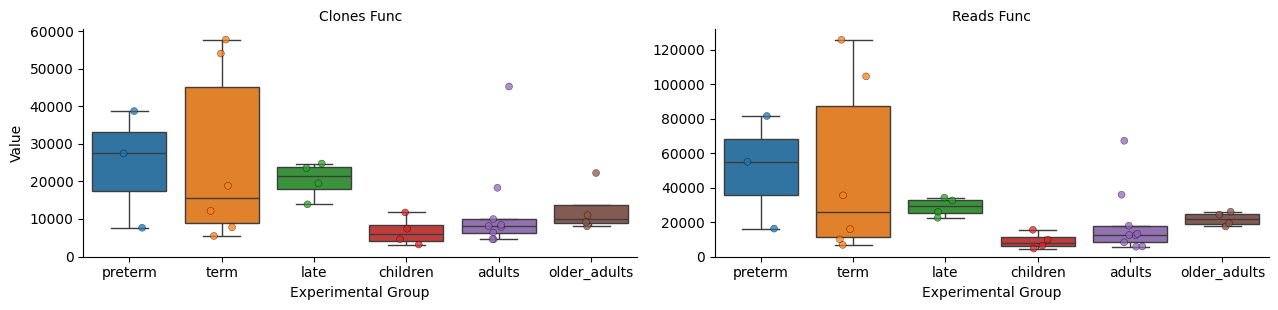

In [9]:
# Сравниваем объём функциональной части репертуаров между экспериментальными группами.
rsplot.clonoset_stats(clonoset_stats_treg, metadata=metadata, group="experimental_group", properties=["clones_func", "reads_func"], aspect=2)

In [10]:
# Сортируем образцы по числу функциональных наблюдений: это помогает выбрать downsample.
clonoset_stats_treg.sort_values(by="reads_func")

,sample_id,chain,clones,clones_func,clones_func_singletons,clones_func_non_singletons,clones_nonfunc,clones_nonfunc_freq,reads,reads_func,reads_nonfunc,reads_nonfunc_freq,umi,umi_func,umi_nonfunc,umi_nonfunc_freq,reads_per_umi
11,c3_nTreg_TRB_1,TRB,3307,3201,2265,936,106,0.032053,4756,4644,112,0.023549,NaN,NaN,NaN,NaN,NaN
9,a11_nTreg_TRB_1,TRB,4796,4585,3713,872,211,0.043995,5953,5724,229,0.038468,NaN,NaN,NaN,NaN,NaN
26,a10_nTreg_TRB_1,TRB,4862,4636,3702,934,226,0.046483,6115,5872,243,0.039738,NaN,NaN,NaN,NaN,NaN
8,c4_nTreg_TRB_1,TRB,4819,4633,3409,1224,186,0.038597,6622,6416,206,0.031108,NaN,NaN,NaN,NaN,NaN
24,UCB12_nTreg_TRB_1,TRB,5778,5488,4530,958,290,0.050190,7082,6781,301,0.042502,NaN,NaN,NaN,NaN,NaN
15,a7_nTreg_TRB_1,TRB,6711,6402,5040,1362,309,0.046044,8616,8275,341,0.039578,NaN,NaN,NaN,NaN,NaN
2,c5_nTreg_TRB_1,TRB,7674,7415,5724,1691,259,0.033750,10177,9891,286,0.028103,NaN,NaN,NaN,NaN,NaN
21,UCB13_nTreg_TRB_1,TRB,8158,7790,6264,1526,368,0.045109,10381,9977,404,0.038917,NaN,NaN,NaN,NaN,NaN
4,a1_nTreg_TRB_1,TRB,8186,7864,5162,2702,322,0.039335,12793,12413,380,0.029704,NaN,NaN,NaN,NaN,NaN
14,a3_nTreg_TRB_1,TRB,8970,8455,5985,2470,515,0.057414,13118,12509,609,0.046425,NaN,NaN,NaN,NaN,NaN


In [11]:
# Заранее определяем фильтр продуктивных клонов и фильтр с равной глубиной 4500.
# # Внимание: отдельная колонка UMI в этих клоносетах отсутствует; см. примечание выше.
func_filter = clf.Filter(functionality="f", by_umi=True)
downsample_filter = clf.Filter(functionality="f", downsample=4500, by_umi=True, seed=100)

**Один фильтр — одинаковые правила для всех образцов.** `clf.Filter` хранит настройки, которые передаются в вычислительные функции. Фильтры нужны, чтобы исключать нефункциональные последовательности, ограничивать число клонотипов или выравнивать число наблюдений между образцами.

- `functionality='f'` оставляет продуктивные последовательности (в рамке считывания, без стоп-кодона в соответствующем участке). Непродуктивные транскрипты могут реже наблюдаться из-за отбора и, в части случаев, NMD; их доля в данных **не** обязана быть равна доле непроизводительных перестроек на уровне ДНК.
- `top` оставляет наиболее многочисленные клонотипы; `downsample` выбирает заданное **число наблюдений** случайным образом. Это разные процедуры: первая обогащает частые клоны, вторая стандартизирует глубину.
- `seed` фиксирует случайность и делает сравнение воспроизводимым. `by_umi=True` предпочтителен при наличии UMI-счётчиков; когда отдельного поля нет, проверяйте сообщения библиотеки о фактически выбранном счётчике.

**Вопрос:** почему нельзя напрямую сравнить число обнаруженных клонотипов в образцах с существенно разной глубиной?

## Filters

**`Filter` - is a special object, that may be used as a setup for Postanalysis.** You can easily create or change one and put it as an argument to other functions for individual clonoset or multi-clonoset metrics

Here is a basic default filter with all possible options:

In [12]:
# Просматриваем все настройки объекта Filter. Это пример конфигурации, не запуск анализа.
clf.Filter(name="default_filter",         # <- name of the filter
           functionality="a",             # <- functional clonotypes = clonotypes without STOP codons or out-of-frames (OOFs) in the CDR3 region, "a" = all clonotypes, "f" = leave only functional, "n" = leave only non-functional
           downsample=None,               # <- randomly downsample to this count value
           top=None,                      # <- take top-N clonotypes
           by_umi=False,                  # <- False = count by read-counts, True = count by UMI counts, if such a column exists
           mix_tails=False,               # <- True = mix all clonotypes with same counts randomly
           count_threshold=None,          # <- set minimal count value for clonotypes, others will be filtered out
           unweight=False,                # <- set count=1 to all clonotypes
           seed=None,                     # <- set seed for random processes, like downsampling and mixing tails for reproducibility
           recount_fractions=True,        # <- should you normalize all fractions to sum to 1 after filtering procedures?
           white_list=[],                 # <- a list of clonotypes, that should be left in the clonoset (the syntax for the list is below)
           black_list=[],                 # <- a list of clonotypes, that should be filtered out
           pool_clonoset_by="",           # <- combine clonotypes into one by CDR3, V or J equlity
           convert=True,                  # <- convert=False preserves all the columns of the original clonoset table. Otherwise the clonoset will be converted into VDJtools-like format for simplicity
           ignore_small_clonosets=False   # <- =True suppreses the warnings when clonoset is smaller than the given downsample or top values.
          )

Here are some examples of useful filters:

### Functional

functionality options: `a` (default) - any. `f` - only functional, `n` - only non-functional

In [13]:
# Оставляем функциональные клонотипы и используем счётчики UMI, если они доступны.
func_filter = clf.Filter(functionality="f", by_umi=True)
func_filter

**`top=4000` не означает 4000 наблюдений.** Это выбор 4000 клонотипов с наибольшими счётчиками. Если несколько клонотипов имеют одинаковый счётчик около границы отсечения, `mix_tails=True` перемешивает их для уменьшения зависимости результата от порядка строк. `seed=100` делает такое перемешивание повторяемым.

### Top

top clonotypes by count. Recommended to mix the tails and specify the seed

In [14]:
# Сохраняем 4000 наиболее частых клонов; смешиваем равные по счётчику хвосты случайно.
top_filter = clf.Filter(functionality="f", top=4000, by_umi=True, mix_tails=True, seed=100)
top_filter

**Зачем нужен даунсэмпл.** Сравнение разнообразия без контроля глубины может дать ложное преимущество глубоко прочитанному образцу: чем больше наблюдений, тем больше редких клонотипов можно обнаружить. `downsample=4500` задаёт общую глубину для примера с nTreg, но **не является универсальным порогом** для остальных клеточных популяций. Его выбирают после изучения распределения размеров образцов; слишком высокий порог может привести к исключению малых образцов.

### Downsample

Take a random sample by counts (UMI or reads). Seed is recommended to use for reproducibility.

Usually used for Diversity metrics, Convergence and other procedures, which require sample normalization

In [15]:
# Случайно приводим образцы к глубине 4500 наблюдений с фиксированным seed.
downsample_filter = clf.Filter(functionality="f", downsample=4500, by_umi=True, seed=100)
downsample_filter

# Analysis

**Свойства CDR3.** CDR3 — наиболее вариабельная область рецептора, в формировании которой участвуют V(D)J-рекомбинация, обрезание концов и вставки нуклеотидов. Помимо длины можно описывать физико-химические свойства аминокислотной последовательности (заряд, гидрофобность и др.). Графики ниже сравнивают распределения **по образцам**, сгруппированным по `experimental_group`; отдельные точки — это не независимые T-клетки.

Найденное различие не обязательно означает различие антигенной специфичности: это косвенные характеристики репертуара.

## CDR3 properties

Calculates different properties for CDR3 region. In this case we passed `func_filter` to make calculations only for 'functional' clonotypes

In [17]:
from pathlib import Path

stats.AA_PROPS_PATH = str(
    Path(stats.__file__).parent / "resourses" / "aa_property_table.txt"
)

In [18]:
# Считаем длину, вставки и свойства аминокислот CDR3 для функциональных клонов.
cdr3_properties = stats.calc_cdr3_properties(clonosets_treg, cl_filter=func_filter, cpu=2)
cdr3_properties

Using 2 cores
CalcCDR3aaProperties |##################################################| 30/30 calcultaion(s) processed


,sample_id,chain,mean_cdr3nt_len,mean_insert_size,zero_insert_freq,mean_frequency,cdr3_5_hydropathy,cdr3_full_hydropathy,cdr3_5_charge,cdr3_full_charge,...,cdr3_5_turn,cdr3_full_turn,cdr3_5_alpha,cdr3_full_alpha,cdr3_5_beta,cdr3_full_beta,cdr3_5_core,cdr3_full_core,cdr3_5_disorder,cdr3_full_disorder
0,UCB5_nTreg_TRB_1,TRB,40.651386,3.244254,0.258438,0.000036,-4.612540,-3.416064,0.049389,-0.214595,...,5.796363,14.020616,4.534407,13.343114,4.827933,13.326135,0.293223,0.732550,2.180644,2.063300
1,UCB2_nTreg_TRB_2,TRB,42.878670,5.885384,0.083533,0.000019,-3.662624,-3.013615,0.140515,-0.161126,...,5.784605,14.821888,4.501538,14.030488,4.847419,14.058223,0.290122,0.772695,2.147172,2.359992
2,c5_nTreg_TRB_1,TRB,42.760388,6.987261,0.026893,0.000135,-3.883733,-3.531837,0.099990,-0.291983,...,5.830545,14.798221,4.496963,14.041847,4.820060,13.970178,0.289050,0.767937,2.353250,2.610555
3,o6_nTreg_TRB_1,TRB,43.006296,7.488809,0.021884,0.000045,-3.759707,-2.985123,0.159481,-0.119937,...,5.808720,14.859243,4.486181,14.086008,4.836284,14.080999,0.289786,0.772577,2.303144,2.507659
4,a1_nTreg_TRB_1,TRB,43.030533,7.643599,0.020301,0.000127,-3.449078,-3.180424,0.182712,-0.180214,...,5.786197,14.826571,4.482052,14.129119,4.856840,14.097187,0.289956,0.773829,2.233787,2.510997
5,o1_nTreg_TRB_1,TRB,43.274845,7.329689,0.023529,0.000124,-3.639415,-3.899485,0.038184,-0.389569,...,5.829768,14.999089,4.498350,14.210788,4.831061,14.137766,0.289456,0.777801,2.334784,2.728876
6,a16_nTreg_TRB_1,TRB,43.288565,7.518935,0.021635,0.000022,-3.637947,-3.260799,0.168276,-0.186221,...,5.802027,14.949630,4.489763,14.209245,4.839746,14.159931,0.289714,0.778259,2.293059,2.592411
7,UCB7_nTreg_TRB_1,TRB,42.271715,6.227241,0.054915,0.000051,-4.114073,-3.384604,0.194988,-0.109135,...,5.783297,14.601701,4.507380,13.821019,4.834150,13.867632,0.289969,0.760437,2.208059,2.289736
8,c4_nTreg_TRB_1,TRB,43.063747,7.019327,0.020885,0.000216,-3.611206,-3.647911,0.159601,-0.255923,...,5.816397,14.864250,4.484702,14.155335,4.840164,14.088734,0.290025,0.775748,2.296135,2.643547
9,a11_nTreg_TRB_1,TRB,43.791929,8.001922,0.015549,0.000218,-3.306866,-3.434609,0.210168,-0.209294,...,5.767315,15.088671,4.498092,14.403031,4.862331,14.334493,0.289434,0.788948,2.225192,2.698113


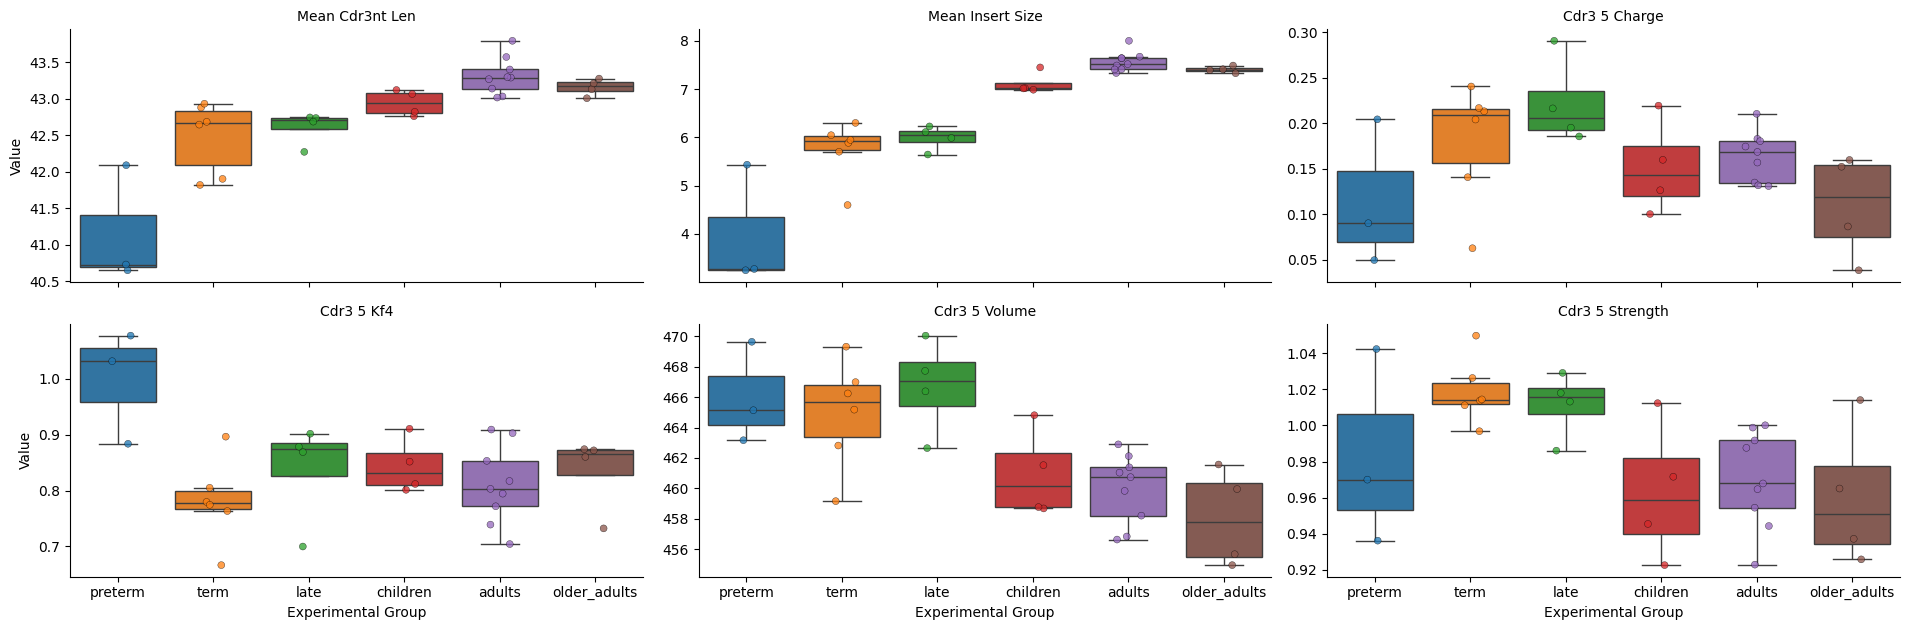

In [19]:
# Отображаем свойства CDR3 по экспериментальным группам, один образец — одно наблюдение.
rsplot.cdr3aa_stats(cdr3_properties,
                     metadata=metadata,
                     properties=None,
                     group="experimental_group",
                     split=None,
                     palette=None,
                     height=3.2,
                     aspect=2,
                    )

In [20]:
# Записываем рассчитанные свойства CDR3 в CSV для повторного использования.
cdr3_properties.to_csv(os.path.join(WORKING_DIR, "cdr3_properties.csv"), index=False)

**Распределение длин CDR3.** Здесь сравниваются `preterm` (недоношенные) и `late` (поздний срок гестации) **в одной клеточной популяции**. `seq_type='aa'` задаёт длину в аминокислотах, а `count_by_freq=True` — относительные частоты, а не абсолютное число последовательностей. Ненулевые вставки при рекомбинации могут увеличивать длину CDR3; биологическая гипотеза о возрастном различии связана в том числе с активностью TdT.

На первом графике смотрим профили отдельных образцов, на втором — их группировку. **Вопрос:** сдвиг распределения отражает изменение средней длины, формы распределения или обоих параметров?

## CDR3len distributions

In [21]:
# Выбираем только nTreg из групп preterm и late для иллюстрации сравнения сроков.
preterm_late_tregs = clonosets_treg.query("experimental_group in ['preterm', 'late']")
preterm_late_tregs

,sample_id,chain,filename,experimental_group,donor_id,subset,source
0,UCB5_nTreg_TRB_1,TRB,/home/anna/Bioinformatics305/homework_immune/d...,preterm,UCB5,nTreg,UCB
7,UCB7_nTreg_TRB_1,TRB,/home/anna/Bioinformatics305/homework_immune/d...,late,UCB7,nTreg,UCB
16,UCB11_nTreg_TRB_1,TRB,/home/anna/Bioinformatics305/homework_immune/d...,preterm,UCB11,nTreg,UCB
17,UCB4_nTreg_TRB_3,TRB,/home/anna/Bioinformatics305/homework_immune/d...,late,UCB4,nTreg,UCB
20,UCB9_nTreg_TRB_1,TRB,/home/anna/Bioinformatics305/homework_immune/d...,late,UCB9,nTreg,UCB
22,UCB8_nTreg_TRB_1,TRB,/home/anna/Bioinformatics305/homework_immune/d...,late,UCB8,nTreg,UCB
28,UCB1_nTreg_TRB_2,TRB,/home/anna/Bioinformatics305/homework_immune/d...,preterm,UCB1,nTreg,UCB


In [22]:
# Получаем частотное распределение длины CDR3 в аминокислотах для каждого образца.
# # zero_fill=True оставляет нулевые частоты для отсутствующих в образце длин.
cdr3_len_distribs = stats.cdr3_length_distributions(
                                                        preterm_late_tregs,
                                                        cl_filter=func_filter,
                                                        cpu=None,
                                                        count_by_freq=True,
                                                        seq_type="aa",
                                                        table="long",
                                                        zero_fill=True,
                                                        verbose=True,
                                                        drop_small_samples=False,
                                                    )
cdr3_len_distribs

Using all available worker processes by default. Set cpu=1 or another integer to change this.
CalcCDR3LengthDistribution |##################################################| 7/7 calcultaion(s) processed


,sample_id,chain,cdr3_length,freq
0,UCB11_nTreg_TRB_1,TRB,5,0.000000
1,UCB11_nTreg_TRB_1,TRB,6,0.000000
2,UCB11_nTreg_TRB_1,TRB,7,0.000740
3,UCB11_nTreg_TRB_1,TRB,8,0.000740
4,UCB11_nTreg_TRB_1,TRB,9,0.001356
...,...,...,...,...
135,UCB9_nTreg_TRB_1,TRB,20,0.001519
136,UCB9_nTreg_TRB_1,TRB,21,0.000438
137,UCB9_nTreg_TRB_1,TRB,22,0.000000
138,UCB9_nTreg_TRB_1,TRB,23,0.000058


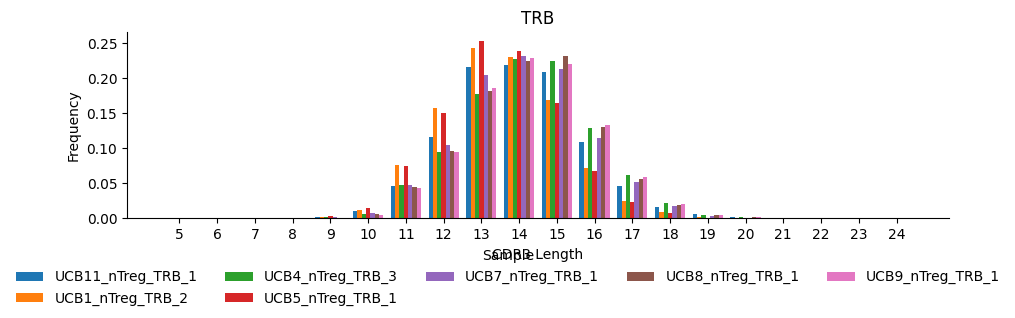

In [23]:
# Показываем распределения длин для отдельных образцов без разбиения по группам.
rsplot.cdr3_length_distributions(cdr3_len_distribs)

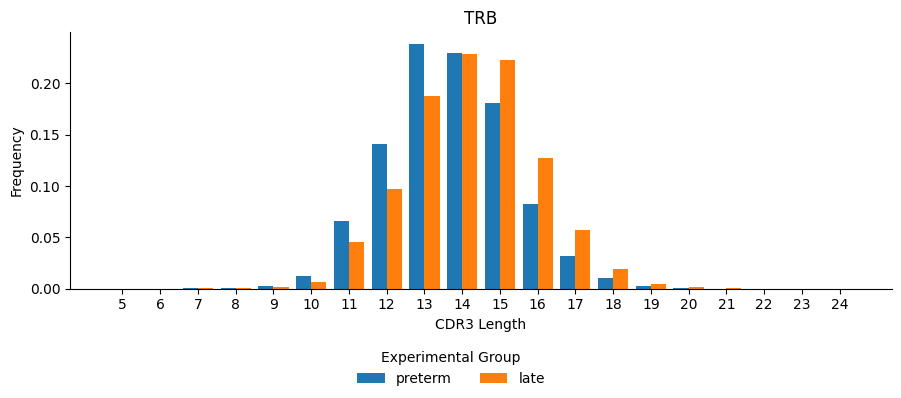

In [24]:
# Показываем те же распределения, добавляя возрастные/экспериментальные группы.
rsplot.cdr3_length_distributions(cdr3_len_distribs, metadata=metadata, group="experimental_group", height=4)

**Использование сегментов (segment usage).** При сборке TCR используются разные V- и J-сегменты. Их частоты не обязаны быть одинаковыми: влияют особенности рекомбинации, отбора и экспансии клонотипов. Это **описательная метрика**; высокое использование одного сегмента само по себе не доказывает ответ на определённый антиген.

`v_usage`/`j_usage` — таблицы относительного использования сегментов по образцам; тепловая карта, boxplot и barplot показывают одни данные разными способами. `combine_families=True` объединяет родственные V-гены по семействам, поэтому детализация становится грубее.

## Segment usage

### V-usage

In [25]:
# Считаем частоту использования каждого V-сегмента в каждом функциональном репертуаре.
v_usage = stats.calc_segment_usage(clonosets_treg, segment="v", cl_filter=func_filter, table="long")
v_usage

Using all available worker processes by default. Set cpu=1 or another integer to change this.


CalcSegmentUsage |##################################################| 30/30 calcultaion(s) processed


,sample_id,chain,v,usage
0,UCB5_nTreg_TRB_1,TRB,TRBV1,0.000255
1,UCB2_nTreg_TRB_2,TRB,TRBV1,0.000392
2,c5_nTreg_TRB_1,TRB,TRBV1,0.000202
3,o6_nTreg_TRB_1,TRB,TRBV1,0.000077
4,a1_nTreg_TRB_1,TRB,TRBV1,0.000242
...,...,...,...,...
1825,a5_nTreg_TRB_1,TRB,TRBV17,0.000000
1826,a10_nTreg_TRB_1,TRB,TRBV17,0.000000
1827,UCB6_nTreg_TRB_1,TRB,TRBV17,0.000000
1828,UCB1_nTreg_TRB_2,TRB,TRBV17,0.000049


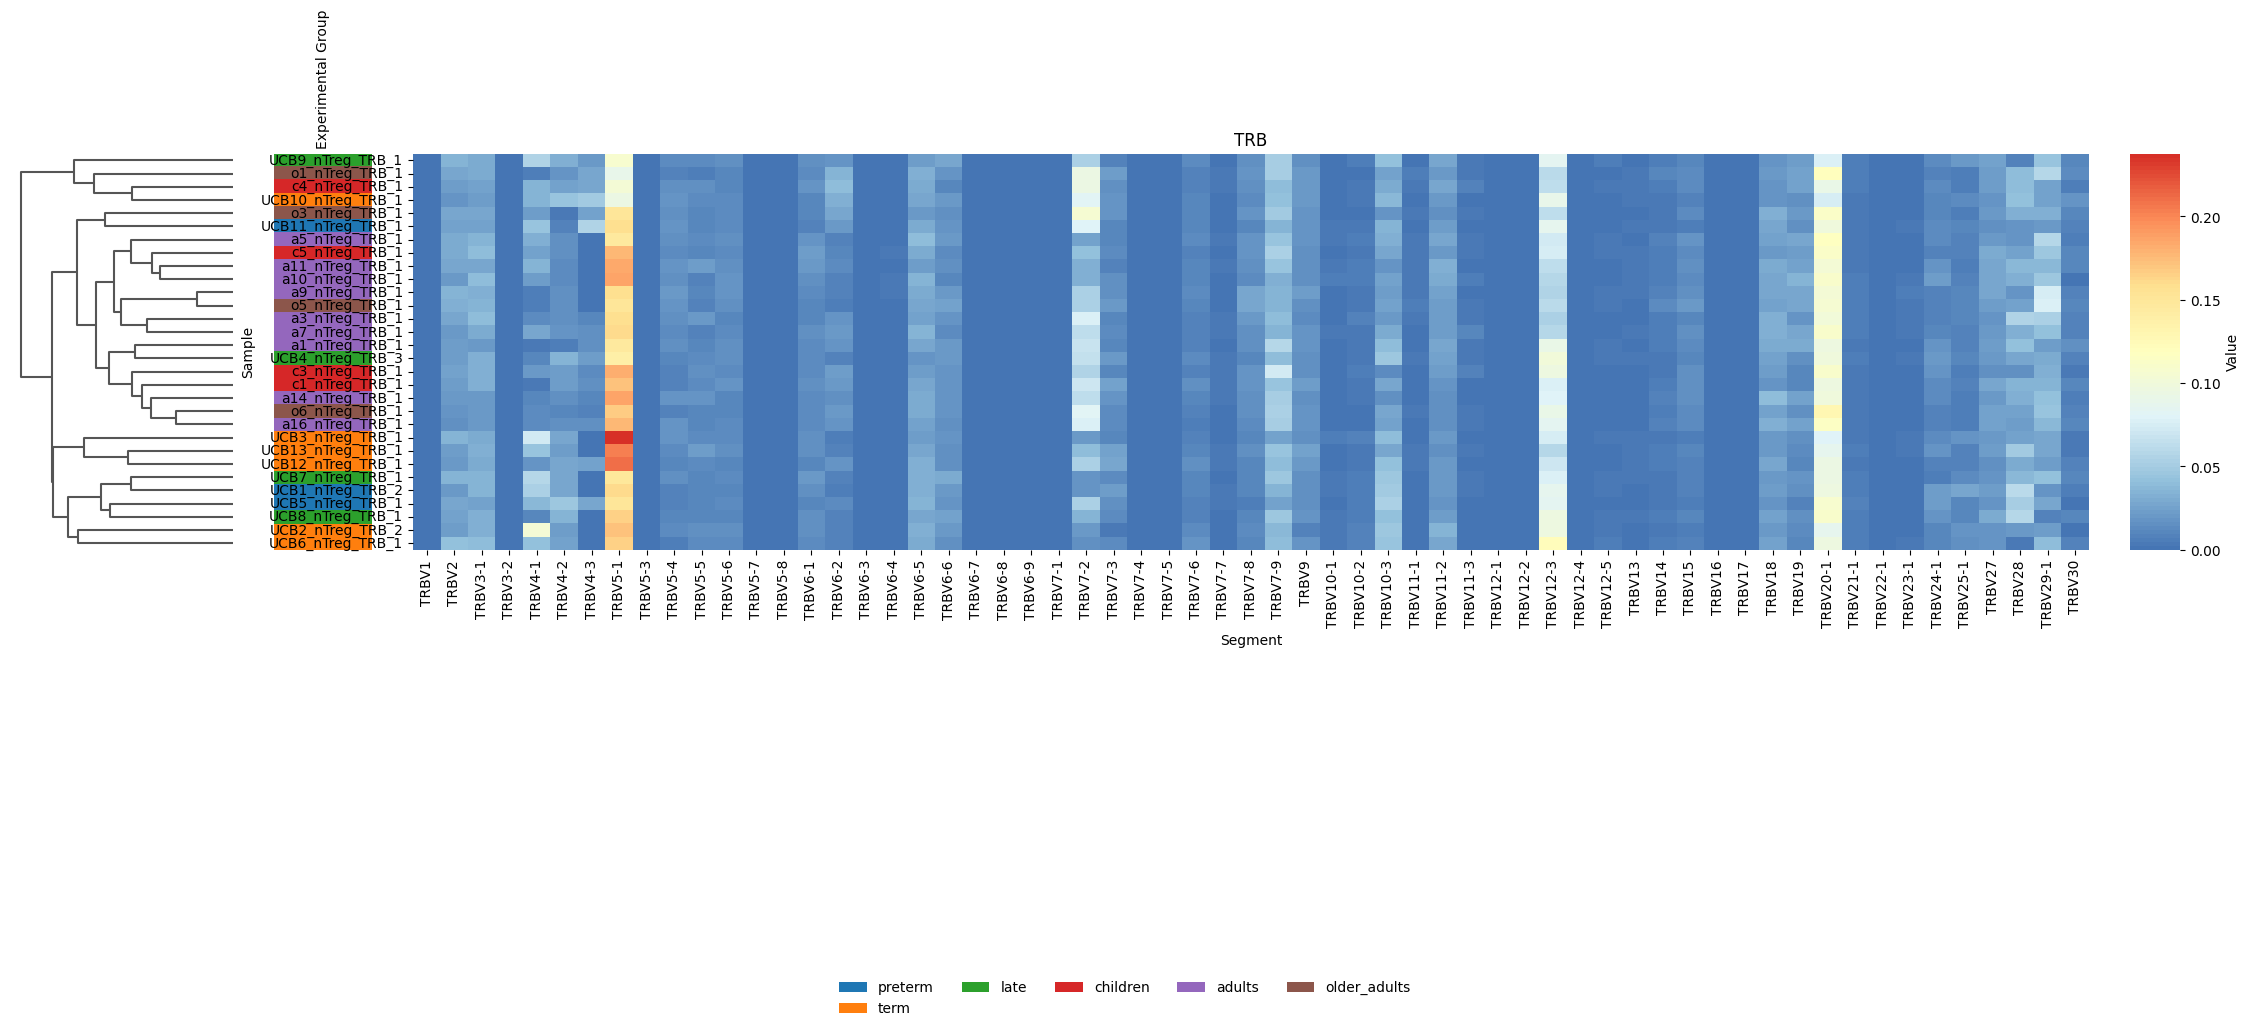

In [26]:
# Тепловая карта: образцы или группы сопоставляются по профилям использования V.
rsplot.segment_usage(v_usage, metadata=metadata, group="experimental_group", plot_type="heatmap", height=7)

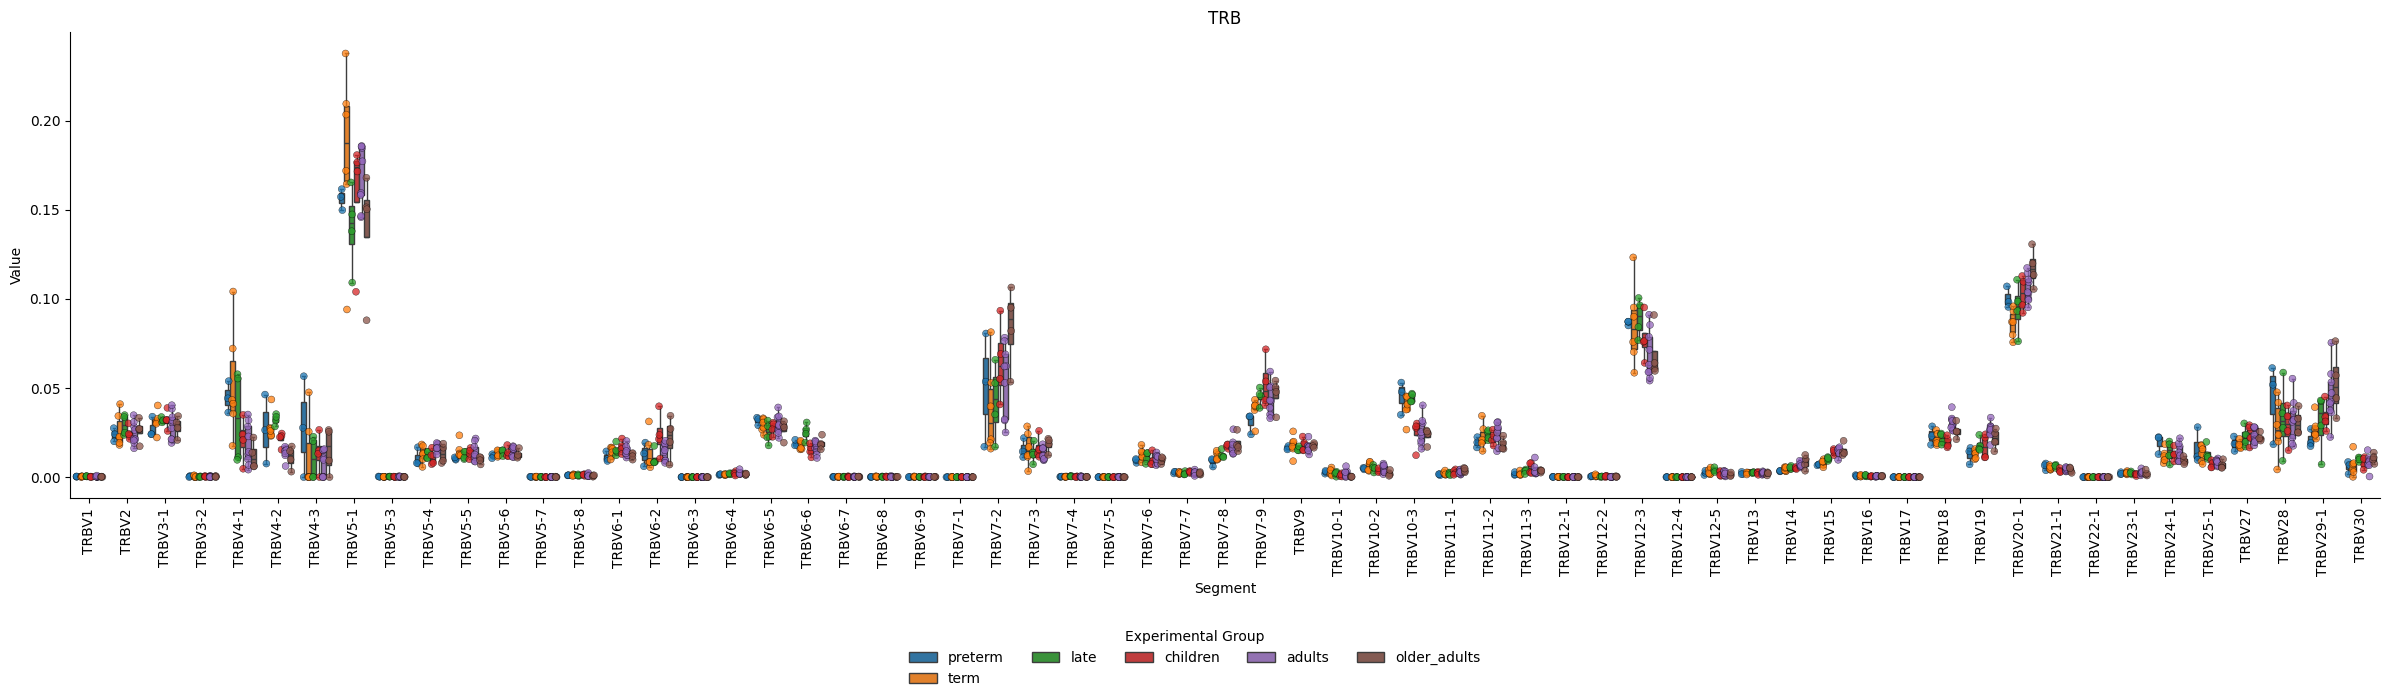

In [27]:
# Boxplot показывает вариацию использования V-сегментов между образцами групп.
rsplot.segment_usage(v_usage, metadata=metadata, group="experimental_group", plot_type="boxplot", height=7, )

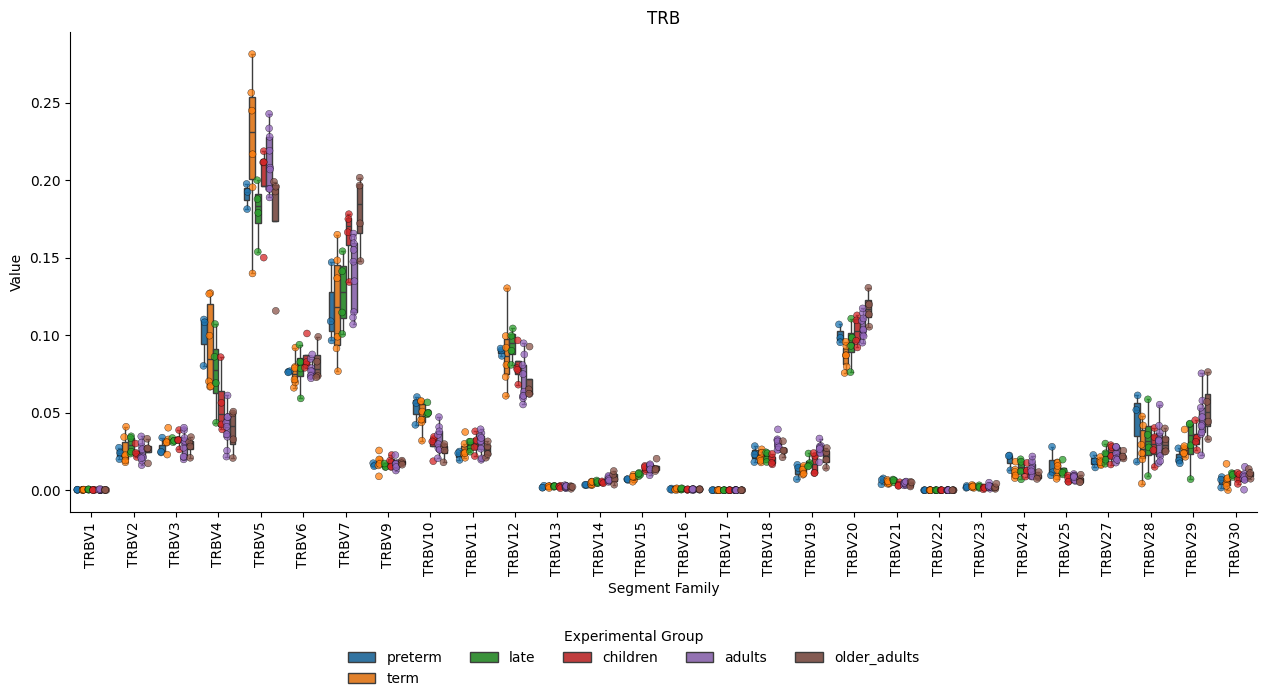

In [28]:
# Объединяем V-гены по семействам, чтобы увидеть более крупные закономерности.
rsplot.segment_usage(v_usage, metadata=metadata, group="experimental_group", plot_type="boxplot", height=7, combine_families=True)

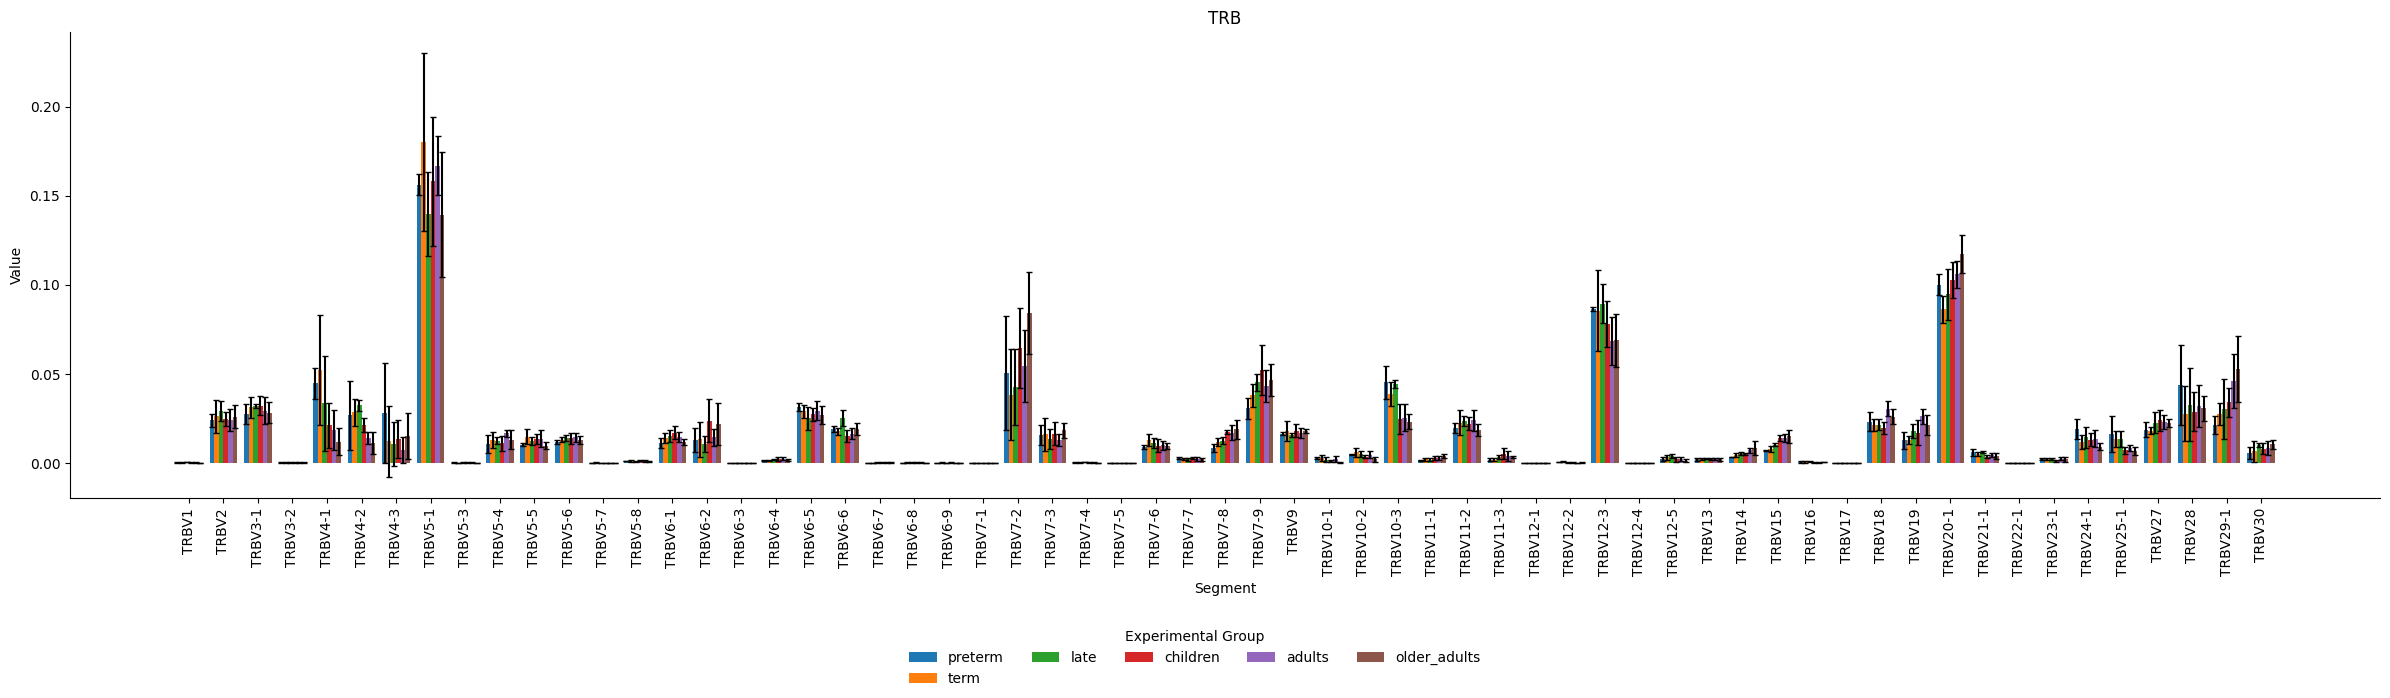

In [29]:
# Barplot показывает частоты отдельных V-генов.
rsplot.segment_usage(v_usage, metadata=metadata, group="experimental_group", plot_type="barplot", height=7)

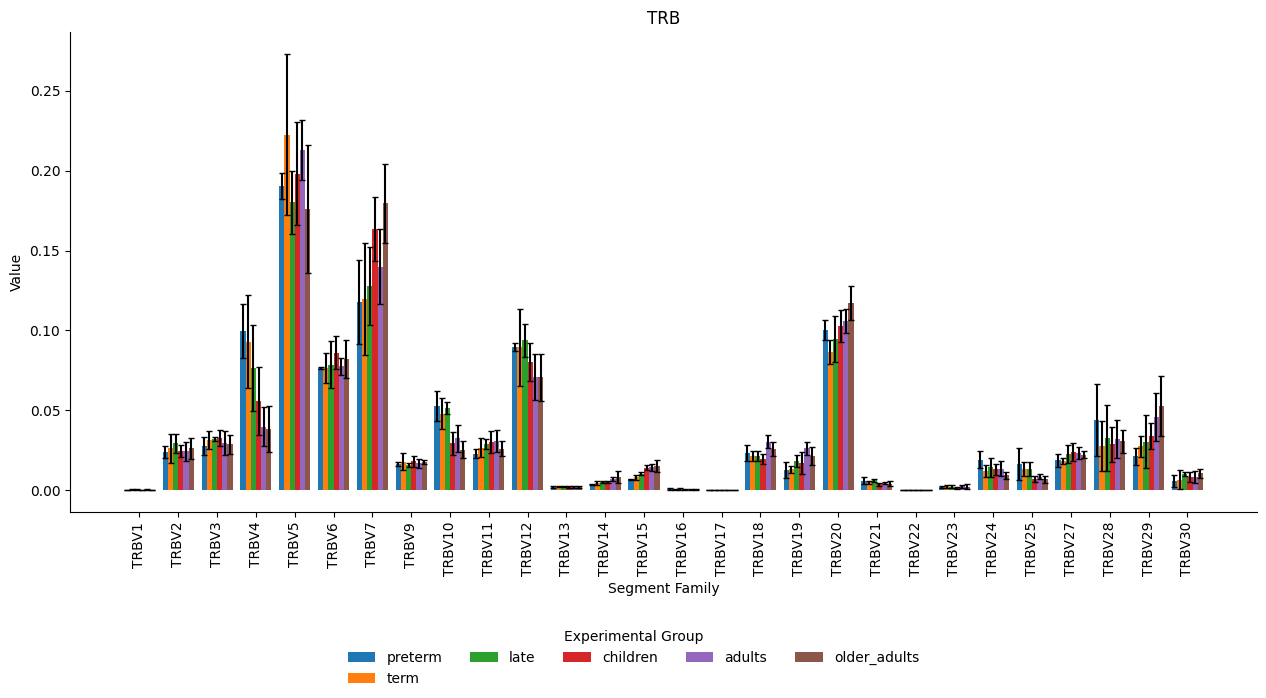

In [30]:
# Barplot для частот V-семейств вместо отдельных V-генов.
rsplot.segment_usage(v_usage, metadata=metadata, group="experimental_group", plot_type="barplot", height=7, combine_families=True)

### J-usage

In [31]:
# Считаем частоты использования J-сегментов вместо V-сегментов.
j_usage = stats.calc_segment_usage(clonosets_treg, segment="j", cl_filter=func_filter)
j_usage

Using all available worker processes by default. Set cpu=1 or another integer to change this.
CalcSegmentUsage |##################################################| 30/30 calcultaion(s) processed


,sample_id,chain,j,usage
0,UCB5_nTreg_TRB_1,TRB,TRBJ1-1,0.092832
1,UCB2_nTreg_TRB_2,TRB,TRBJ1-1,0.101551
2,c5_nTreg_TRB_1,TRB,TRBJ1-1,0.110302
3,o6_nTreg_TRB_1,TRB,TRBJ1-1,0.159404
4,a1_nTreg_TRB_1,TRB,TRBJ1-1,0.103440
...,...,...,...,...
385,a5_nTreg_TRB_1,TRB,TRBJ2-7,0.125299
386,a10_nTreg_TRB_1,TRB,TRBJ2-7,0.235525
387,UCB6_nTreg_TRB_1,TRB,TRBJ2-7,0.135633
388,UCB1_nTreg_TRB_2,TRB,TRBJ2-7,0.167202


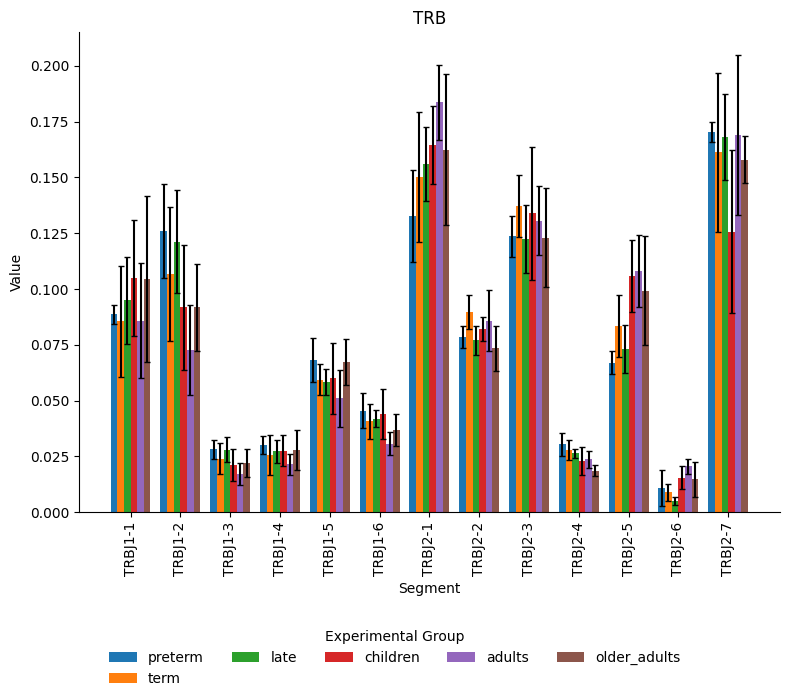

In [32]:
# Отображаем J-usage по экспериментальным группам.
rsplot.segment_usage(j_usage, metadata=metadata, group="experimental_group", plot_type="barplot", height=7)

**Конвергенция нуклеотидных последовательностей.** Разные CDR3 на уровне ДНК могут кодировать **одинаковую CDR3 на уровне белка** благодаря вырожденности генетического кода и независимым событиям перестройки. Простая мера — число различных CDR3nt, делённое на число различных CDR3aa. При добавлении требований совпадения V или V+J получаются более строгие варианты (`convergence_v`, `convergence_vj`).

Конвергенция зависит также от длины CDR3 и механизма генерации последовательностей; **её увеличение само по себе не доказывает антиген-индуцированную экспансию**. Для сравнения образцов применён одинаковый даунсэмпл.

## Convergence

In [33]:
# Вычисляем конвергенцию после стандартизации глубины образцов.
# # Функция делает случайные повторы: фиксируем seed для воспроизводимости.
convergence = stats.calc_convergence(clonosets_treg,
                                     cl_filter=downsample_filter,
                                     seed=42,
                                     cpu=2,
                                     verbose=True
                                    )
convergence

CalcConvergence settings: seed=42, downsample=4500, top=None, iterations=3
Calcultating stats for original clonosets
_________________________________________
Using 2 cores
CalcClonosetStats |##################################################| 30/30 calcultaion(s) processed
WARNING! Following samples have NaN downsample counts ('umi_func'): UCB5_nTreg_TRB_1, UCB2_nTreg_TRB_2, c5_nTreg_TRB_1, o6_nTreg_TRB_1, a1_nTreg_TRB_1, o1_nTreg_TRB_1, a16_nTreg_TRB_1, UCB7_nTreg_TRB_1, c4_nTreg_TRB_1, a11_nTreg_TRB_1, c1_nTreg_TRB_1, c3_nTreg_TRB_1, UCB3_nTreg_TRB_1, o3_nTreg_TRB_1, a3_nTreg_TRB_1, a7_nTreg_TRB_1, UCB11_nTreg_TRB_1, UCB4_nTreg_TRB_3, UCB10_nTreg_TRB_1, a14_nTreg_TRB_1, UCB9_nTreg_TRB_1, UCB13_nTreg_TRB_1, UCB8_nTreg_TRB_1, a9_nTreg_TRB_1, UCB12_nTreg_TRB_1, a5_nTreg_TRB_1, a10_nTreg_TRB_1, UCB6_nTreg_TRB_1, UCB1_nTreg_TRB_2, o5_nTreg_TRB_1
These samples will be counted by reads instead
Using 2 cores
CalcConvergence |##################################################| 30/30 calculta

,sample_id,chain,convergence,convergence_v,convergence_vj
0,UCB5_nTreg_TRB_1,TRB,1.051474,1.008116,1.008116
1,UCB2_nTreg_TRB_2,TRB,1.008397,1.000926,1.000926
2,c5_nTreg_TRB_1,TRB,1.002462,1.000546,1.000546
3,o6_nTreg_TRB_1,TRB,1.002778,1.000924,1.000924
4,a1_nTreg_TRB_1,TRB,1.002207,1.000000,1.000000
5,o1_nTreg_TRB_1,TRB,1.001534,1.000920,1.000920
6,a16_nTreg_TRB_1,TRB,1.001847,1.000461,1.000461
7,UCB7_nTreg_TRB_1,TRB,1.005964,1.000474,1.000474
8,c4_nTreg_TRB_1,TRB,1.003294,1.000896,1.000896
9,a11_nTreg_TRB_1,TRB,1.001100,1.000275,1.000275


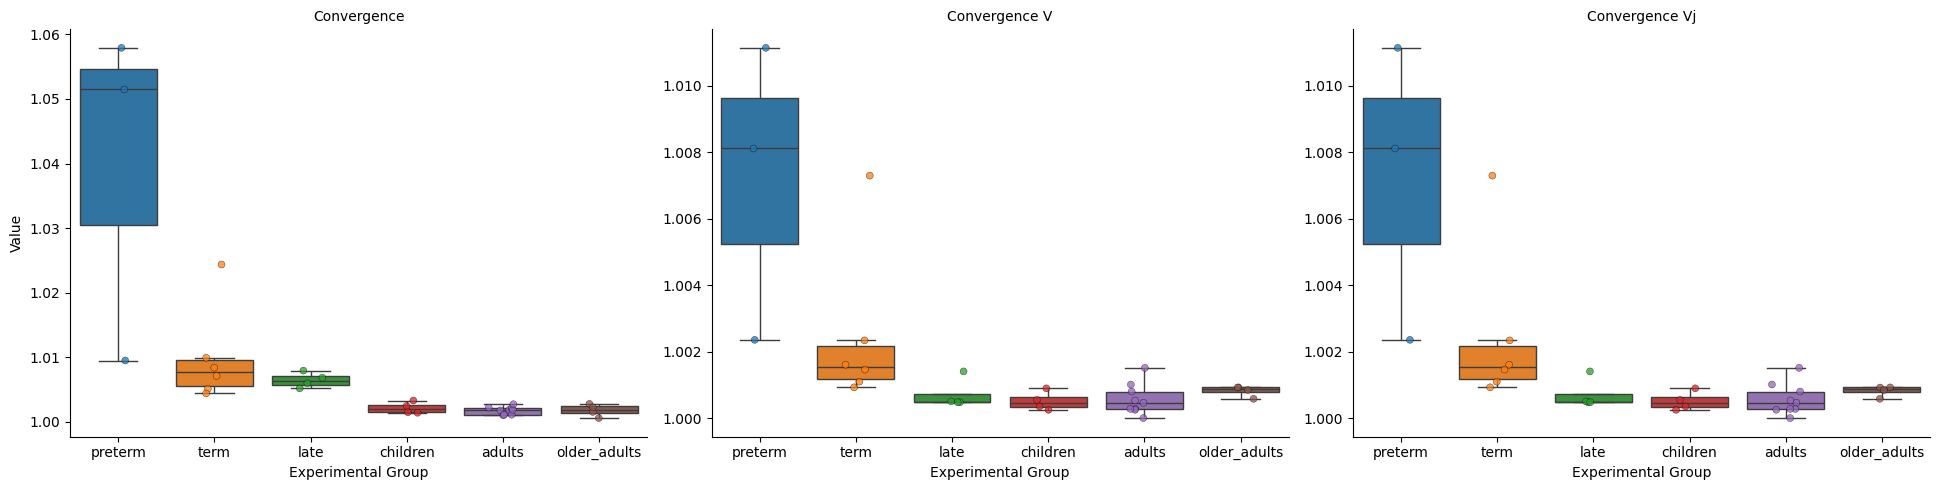

In [34]:
# Показываем конвергенцию и её варианты по экспериментальным группам.
rsplot.convergence(convergence,
                     metadata=metadata,
                     group="experimental_group",
                     height=5,
                     aspect=1.3
                  )

**Альфа-разнообразие — разнообразие *внутри* одного образца.** Несколько важных метрик:

- **`diversity`** — число обнаруженных клонотипов (богатство); чувствительно к глубине наблюдений.
- **`shannon_wiener`**: $H=-\sum_i p_i\ln p_i$; учитывает и богатство, и равномерность частот.
- **`norm_shannon_wiener`**: нормированная мера равномерности, обычно $H/\ln S$ (при $S>1$); ближе к 1, если частоты более равномерны.
- **`clonality`** — показатель противоположной направленности: больший вклад немногих клонов означает более выраженную клональность.
- Дополнительные метрики в таблице (`chao1`, `simpson`, `inverse_simpson`, `d50`, `gini_coefficient` и др.) по-разному чувствительны к редким и частым клонотипам.

`iterations=3` повторяет случайное субсэмплирование несколько раз; сравнивайте группы по распределению **образцов**, не воспринимая эти повторы как новые независимые биологические реплики. В данном примере настройка `seed` в самой функции и в фильтре могут различаться — ориентируйтесь на параметры расчёта в её логе.

## Diversity stats

In [35]:
# Считаем несколько индексов альфа-разнообразия на одинаковой глубине.
# # iterations=3 повторяет случайный выбор; это не три биологических образца.
diversity_stats = stats.calc_diversity_stats(clonosets_treg,
                                             cl_filter=downsample_filter, seed=123, cpu=2,
                                             iterations=3,
                                             drop_small_samples=False, 
                                             verbose=True
                                            )
diversity_stats

CalcDiversityStats settings: seed=123, downsample=4500, top=None, iterations=3
Calcultating stats for original clonosets
_________________________________________
Using 2 cores


CalcClonosetStats |##################################################| 30/30 calcultaion(s) processed
WARNING! Following samples have NaN downsample counts ('umi_func'): UCB5_nTreg_TRB_1, UCB2_nTreg_TRB_2, c5_nTreg_TRB_1, o6_nTreg_TRB_1, a1_nTreg_TRB_1, o1_nTreg_TRB_1, a16_nTreg_TRB_1, UCB7_nTreg_TRB_1, c4_nTreg_TRB_1, a11_nTreg_TRB_1, c1_nTreg_TRB_1, c3_nTreg_TRB_1, UCB3_nTreg_TRB_1, o3_nTreg_TRB_1, a3_nTreg_TRB_1, a7_nTreg_TRB_1, UCB11_nTreg_TRB_1, UCB4_nTreg_TRB_3, UCB10_nTreg_TRB_1, a14_nTreg_TRB_1, UCB9_nTreg_TRB_1, UCB13_nTreg_TRB_1, UCB8_nTreg_TRB_1, a9_nTreg_TRB_1, UCB12_nTreg_TRB_1, a5_nTreg_TRB_1, a10_nTreg_TRB_1, UCB6_nTreg_TRB_1, UCB1_nTreg_TRB_2, o5_nTreg_TRB_1
These samples will be counted by reads instead
Using 2 cores
CalcDiversityStats |##################################################| 30/30 calcultaion(s) processed


,sample_id,chain,diversity,norm_shannon_wiener,clonality,shannon_wiener,chao1,richness,ace,goods_coverage,d50,simpson,inverse_simpson,gini_simpson,berger_parker,gini_coefficient
0,UCB5_nTreg_TRB_1,TRB,4135.0,0.995975,0.004025,8.293729,29457.571429,4135.0,29976.247221,0.152667,0.455865,0.000263,3796.400450,0.999737,0.001111,0.075470
1,UCB2_nTreg_TRB_2,TRB,4335.0,0.998238,0.001762,8.359723,65441.923077,4335.0,64881.011236,0.070889,0.480969,0.000240,4173.536686,0.999760,0.000667,0.035445
2,c5_nTreg_TRB_1,TRB,3856.0,0.993202,0.006798,8.201251,15839.358862,3856.0,15641.354834,0.264444,0.416494,0.000297,3371.628372,0.999703,0.001111,0.125471
3,o6_nTreg_TRB_1,TRB,4364.0,0.998552,0.001448,8.369006,79111.750000,4364.0,78586.830131,0.058667,0.484418,0.000236,4229.323308,0.999764,0.000667,0.029385
4,a1_nTreg_TRB_1,TRB,3719.0,0.991527,0.008473,8.151553,13372.911111,3719.0,13131.608012,0.312889,0.394999,0.000317,3155.188532,0.999683,0.001111,0.149000
5,o1_nTreg_TRB_1,TRB,3403.0,0.987869,0.012131,8.033758,9009.613712,3403.0,8944.194765,0.424444,0.338819,0.000370,2705.772314,0.999630,0.002444,0.197425
6,a16_nTreg_TRB_1,TRB,4350.0,0.998461,0.001539,8.365041,67485.071429,4350.0,67385.123567,0.065556,0.482759,0.000238,4209.979210,0.999762,0.000667,0.032258
7,UCB7_nTreg_TRB_1,TRB,4254.0,0.997427,0.002573,8.334113,41901.795349,4254.0,41923.150978,0.105778,0.471086,0.000248,4029.048945,0.999752,0.000889,0.051891
8,c4_nTreg_TRB_1,TRB,3511.0,0.989029,0.010971,8.074090,10529.857143,3511.0,10340.785980,0.384667,0.359157,0.000350,2855.329949,0.999650,0.001333,0.182379
9,a11_nTreg_TRB_1,TRB,3766.0,0.991878,0.008122,8.166893,14447.991525,3766.0,14371.580606,0.294222,0.402549,0.000312,3208.174905,0.999688,0.001111,0.141715


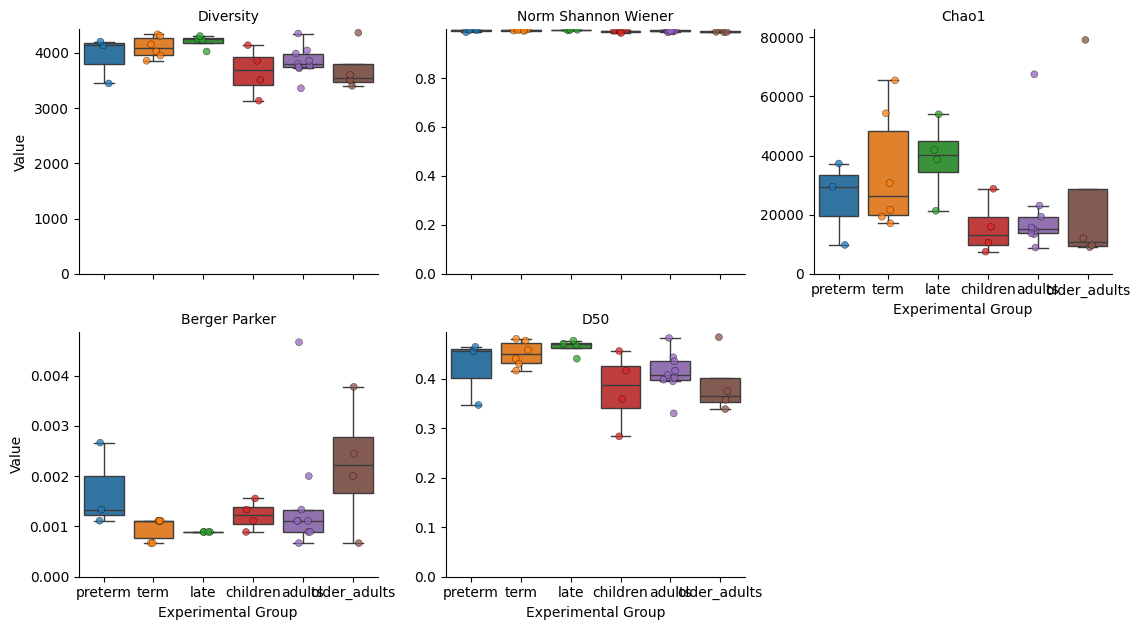

In [36]:
# Визуализируем богатство, равномерность, клональность и другие индексы.
rsplot.diversity_stats(diversity_stats,
                     metadata=metadata,
                     group="experimental_group"
                    )

**Rarefaction (кривые разрежения).** Для каждого образца считаем, сколько различных клонотипов обнаружилось бы при разных глубинах выборки. По оси X — `rarefaction_depth` (число наблюдений), по оси Y — ожидаемое обнаруженное богатство `diversity`.

Если кривая выходит на плато, новые наблюдения добавляют мало новых клонотипов. Для TCR-репертуара всего организма плато часто недостижимо на небольшом образце крови. **Не путать** насыщение секвенирования конкретной библиотеки ридами с насыщением биологического репертуара организма. Два графика отличаются только логарифмической/линейной шкалой X.

## Rarefaction

In [37]:
# Для каждого образца вычисляем богатство при нескольких глубинах наблюдений.
rarefaction_points_ucb = stats.calc_rarefaction_curve(clonosets_treg, cl_filter=clf.Filter(functionality="f", by_umi=True))
rarefaction_points_ucb

Using all available worker processes by default. Set cpu=1 or another integer to change this.
CalcRarefactionPoints |##################################################| 30/30 calcultaion(s) processed


,sample_id,chain,rarefaction_depth,diversity
0,UCB10_nTreg_TRB_1,TRB,32,32.000000
1,UCB10_nTreg_TRB_1,TRB,100,99.666667
2,UCB10_nTreg_TRB_1,TRB,316,315.000000
3,UCB10_nTreg_TRB_1,TRB,1000,988.000000
4,UCB10_nTreg_TRB_1,TRB,3162,3070.000000
...,...,...,...,...
208,o6_nTreg_TRB_1,TRB,316,316.000000
209,o6_nTreg_TRB_1,TRB,1000,994.000000
210,o6_nTreg_TRB_1,TRB,3162,3092.000000
211,o6_nTreg_TRB_1,TRB,10000,9359.000000


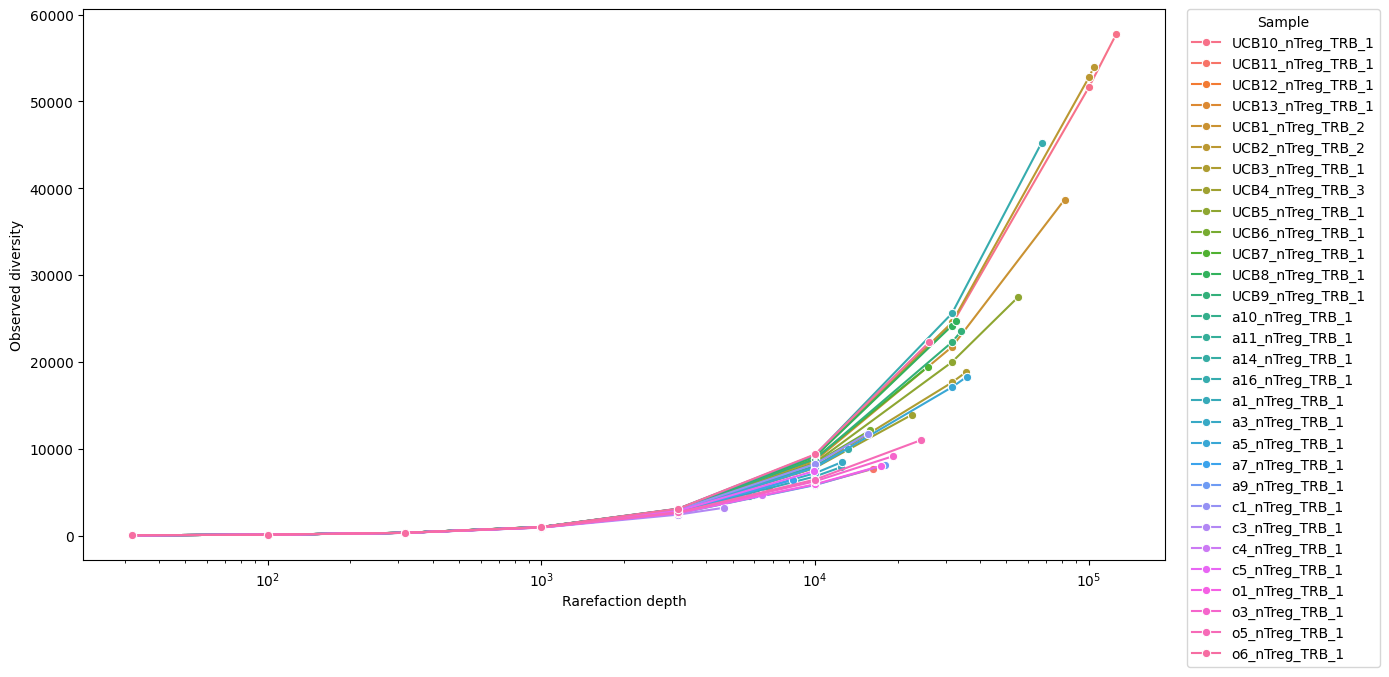

In [38]:
# Строим rarefaction с логарифмической шкалой глубины для обзора широкого диапазона.
rsplot.rarefaction_curve(rarefaction_points_ucb, log_x=True, aspect=2, height=7)

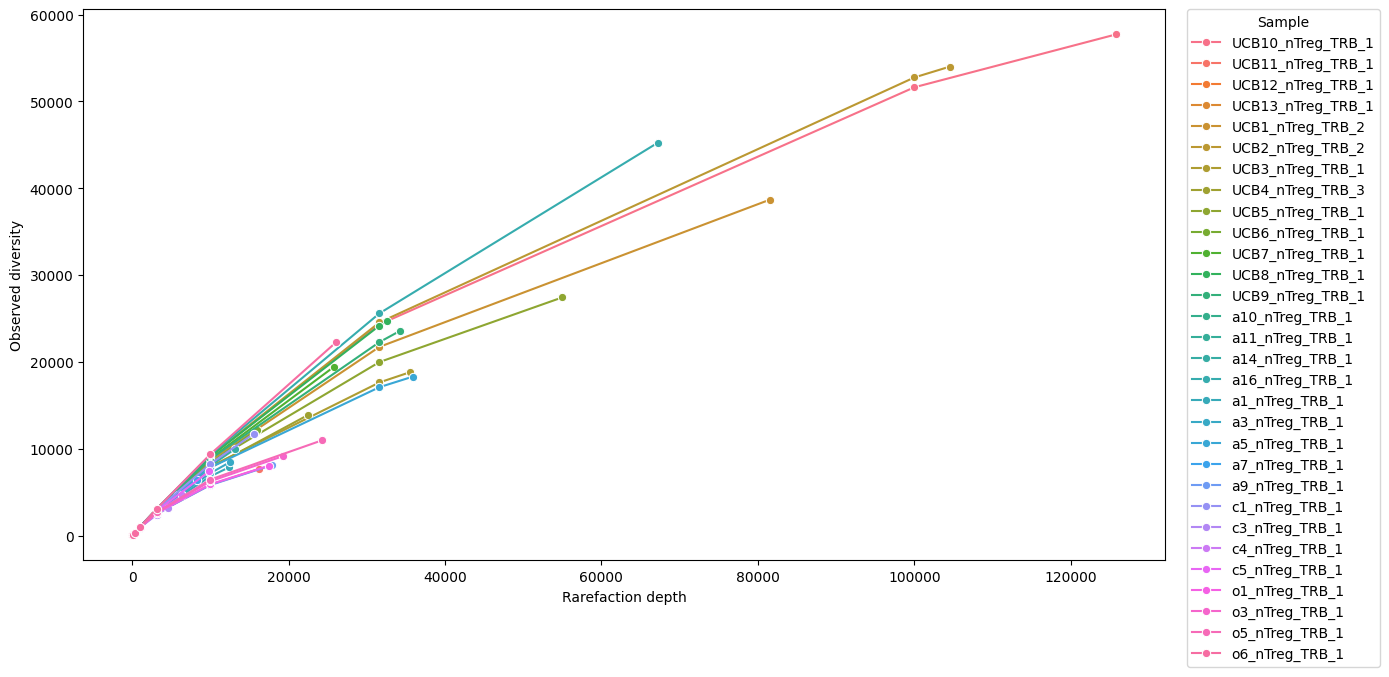

In [39]:
# Строим ту же кривую с обычной шкалой глубины для оценки формы роста.
rsplot.rarefaction_curve(rarefaction_points_ucb, log_x=False, aspect=2, height=7)

**Бета-разнообразие — сходство *между* образцами.** Мы сравниваем не просто численность клонов, а пересечение определённых последовательностей. В этом ноутбуке совпадение задаётся `overlap_type='aaV'`: **одинаковая аминокислотная CDR3 и один V-ген**. Совпадение только CDR3aa без учёта V — менее строгое правило.

Для двух репертуаров $A$ и $B$ метрика **F2** выражается как $F_2(A,B)=\sum_{i\in A\cap B}\sqrt{p_iq_i}$, где $p_i$, $q_i$ — частоты совпавшего клонотипа в каждом образце. Чем больше F2, тем выше сходство по совпадающим последовательностям с учётом их частот. Диагональ матрицы при одинаковых правилах определения клонотипа равна 1; почти нулевые значения между людьми ожидаемы из-за индивидуального разнообразия TCR.

Это **описательная мера сходства**, а не p-value и не результат теста на различия между экспериментальными группами.

## Beta-diversity

### Main function for beta-diversity 

**`beta.metrics`** function calculates a diverse set of Beta-diversity metrics which include (for more detailed explanation refer to **THIS LINK**):

- Number of intersecting clonotypes ('number_of_intersecting_clonotypes')
- Relative diversity ('relative_diversity')
- Pearson correlation ('pearson')
- F1 ('f1') metric - geometric mean of total frequencies of intersecting clonotypes in both samples
- F2 ('f2') metric - sum of geometric means of frequencies of each clonotype in the samples
- ', 'f1', 'f2', 'jaccard', 'jaccard_distance', 'dice', 'dice_distance', 'szymkiewicz_simpson', 'bray_curtis', 'l1', 'total_variation', 'l2', 'morisita_horn', 'jensen_shannon', 'kl_divergence', 'hellinger', 'full_table'

Required input is only the sample_df - DataFrame with the set of repertoires

By default it outputs a dictionary, containing metrics as keys and DataFrames with each metric (or mainly matrices) as values.

In [40]:
# Считаем попарное сходство клоносетов и таблицы пересечений.
# # aaV означает совпадение CDR3aa И V-гена; значение F2 — сходство, не расстояние.
beta_diversity = beta.metrics(clonosets_treg,                     # <- clonosets_df - DataFrame with clonosets - sample_id, filename
                              cl_filter=downsample_filter,        # <- you can use a filter to preprocess all the clonosets before intersecting
                              overlap_type="aaV",                     # <- overlap type - is a defenition of similar clonotypes. aaV = similar clonotypes have same CDR3 amino acid sequence and same V gene, and we are not concidering V gene
                              clonosets_df2=None,                     # <- you can pass a second set of clonosets for intersection, otherwise it will intersect all possible pairs with each other
                              cl_filter2=None,                        # <- you can pass a different filter for second set of clonosets, otherwise it will be preprocessed with cl_filter
                              metrics=None,                           # <- you can limit the metrics to a list or a single metric for simplicity of the output
                              cpu=None                                # <- cpus for parallel calculation (=None means - take all avaiable)
                              )

Intersecting clones in clonosets
--------------------------------------------------
Overlap type: aaV
Reading clonosets |##################################################| 30/30 sample(s) processed
Using all available worker processes by default. Set cpu=1 or another integer to change this.
Intersecting clonosets |##################################################| 435/435 pairs processed


In [41]:
# Смотрим, какие метрики и таблицы вернула функция beta.metrics.
beta_diversity.keys()

dict_keys(['number_of_intersecting_clonotypes', 'relative_diversity', 'pearson', 'f1', 'f2', 'jaccard', 'jaccard_distance', 'dice', 'dice_distance', 'szymkiewicz_simpson', 'bray_curtis', 'l1', 'total_variation', 'l2', 'morisita_horn', 'jensen_shannon', 'kl_divergence', 'hellinger', 'full_table'])

In [42]:
# Отдельно открываем квадратную матрицу попарного сходства F2.
beta_diversity["f2"]

sample2,UCB10_nTreg_TRB_1,UCB11_nTreg_TRB_1,UCB12_nTreg_TRB_1,UCB13_nTreg_TRB_1,UCB1_nTreg_TRB_2,UCB2_nTreg_TRB_2,UCB3_nTreg_TRB_1,UCB4_nTreg_TRB_3,UCB5_nTreg_TRB_1,UCB6_nTreg_TRB_1,...,a7_nTreg_TRB_1,a9_nTreg_TRB_1,c1_nTreg_TRB_1,c3_nTreg_TRB_1,c4_nTreg_TRB_1,c5_nTreg_TRB_1,o1_nTreg_TRB_1,o3_nTreg_TRB_1,o5_nTreg_TRB_1,o6_nTreg_TRB_1
sample1,,,,,,,,,,,,,,,,,,,,,
UCB10_nTreg_TRB_1,1.000000,0.003561,0.003236,0.003113,0.014174,0.004775,0.008861,0.005295,0.014267,0.004694,...,0.000222,0.001274,0.001458,0.000314,0.001517,0.000444,0.001387,0.000667,0.000989,0.003458
UCB11_nTreg_TRB_1,0.003561,1.000000,0.003943,0.002661,0.010814,0.004509,0.009800,0.004970,0.013277,0.005485,...,0.001013,0.001621,0.001425,0.000889,0.001458,0.001659,0.001236,0.002661,0.001529,0.002217
UCB12_nTreg_TRB_1,0.003236,0.003943,1.000000,0.002799,0.008845,0.004146,0.009381,0.003382,0.007436,0.002761,...,0.000667,0.002044,0.001517,0.001425,0.000767,0.002002,0.000829,0.000000,0.000385,0.001013
UCB13_nTreg_TRB_1,0.003113,0.002661,0.002799,1.000000,0.013377,0.003387,0.008854,0.005552,0.010622,0.003297,...,0.000444,0.001747,0.001366,0.000921,0.002913,0.002163,0.002309,0.002577,0.001870,0.001902
UCB1_nTreg_TRB_2,0.014174,0.010814,0.008845,0.013377,1.000000,0.015143,0.028471,0.010335,0.041218,0.013005,...,0.002629,0.003349,0.003165,0.004528,0.002477,0.002590,0.002986,0.001295,0.004655,0.004309
UCB2_nTreg_TRB_2,0.004775,0.004509,0.004146,0.003387,0.015143,1.000000,0.010709,0.002498,0.013847,0.005290,...,0.001333,0.001052,0.001648,0.000667,0.001111,0.000889,0.000981,0.000759,0.002368,0.002092
UCB3_nTreg_TRB_1,0.008861,0.009800,0.009381,0.008854,0.028471,0.010709,1.000000,0.012532,0.029123,0.010669,...,0.002368,0.003751,0.002721,0.001165,0.001073,0.001747,0.001144,0.002924,0.002913,0.003550
UCB4_nTreg_TRB_3,0.005295,0.004970,0.003382,0.005552,0.010335,0.002498,0.012532,1.000000,0.009658,0.003935,...,0.000759,0.001366,0.001902,0.000943,0.002146,0.001648,0.001165,0.002033,0.001425,0.001517
UCB5_nTreg_TRB_1,0.014267,0.013277,0.007436,0.010622,0.041218,0.013847,0.029123,0.009658,1.000000,0.011035,...,0.002943,0.002598,0.002829,0.001609,0.001425,0.002309,0.002347,0.002736,0.002376,0.003035


In [43]:
# Разбираем пересечение двух конкретных репертуаров на уровне клонотипов.
beta_diversity["full_table"].query("pair == 'UCB10_nTreg_TRB_1_vs_UCB11_nTreg_TRB_1'")

,cdr3aa,v,sample1_count,sample2_count,sample1_freq,sample2_freq,sample1,sample2,pair
0,CASSYSTNEQYF,TRBV6-6,1,0,0.000222,0.000000,UCB10_nTreg_TRB_1,UCB11_nTreg_TRB_1,UCB10_nTreg_TRB_1_vs_UCB11_nTreg_TRB_1
1,CASTRPGQVNTGELFF,TRBV5-5,1,0,0.000222,0.000000,UCB10_nTreg_TRB_1,UCB11_nTreg_TRB_1,UCB10_nTreg_TRB_1_vs_UCB11_nTreg_TRB_1
2,CASSRGQAQETQYF,TRBV5-1,0,1,0.000000,0.000222,UCB10_nTreg_TRB_1,UCB11_nTreg_TRB_1,UCB10_nTreg_TRB_1_vs_UCB11_nTreg_TRB_1
3,CASSLEFPGTDTQYF,TRBV12-3,3,0,0.000667,0.000000,UCB10_nTreg_TRB_1,UCB11_nTreg_TRB_1,UCB10_nTreg_TRB_1_vs_UCB11_nTreg_TRB_1
4,CASSQHGQGTDTQYF,TRBV4-3,0,2,0.000000,0.000444,UCB10_nTreg_TRB_1,UCB11_nTreg_TRB_1,UCB10_nTreg_TRB_1_vs_UCB11_nTreg_TRB_1
...,...,...,...,...,...,...,...,...,...
7654,CASSQVGASGNTIYF,TRBV4-3,0,1,0.000000,0.000222,UCB10_nTreg_TRB_1,UCB11_nTreg_TRB_1,UCB10_nTreg_TRB_1_vs_UCB11_nTreg_TRB_1
7655,CASSHPIDRGKHNEQFF,TRBV5-1,1,0,0.000222,0.000000,UCB10_nTreg_TRB_1,UCB11_nTreg_TRB_1,UCB10_nTreg_TRB_1_vs_UCB11_nTreg_TRB_1
7656,CASSIPGQGSQPQHF,TRBV6-6,1,0,0.000222,0.000000,UCB10_nTreg_TRB_1,UCB11_nTreg_TRB_1,UCB10_nTreg_TRB_1_vs_UCB11_nTreg_TRB_1
7657,CASSPKETQYF,TRBV18,0,1,0.000000,0.000222,UCB10_nTreg_TRB_1,UCB11_nTreg_TRB_1,UCB10_nTreg_TRB_1_vs_UCB11_nTreg_TRB_1


**Как читать тепловую карту F2.** Каждая ячейка — результат сравнения **пары образцов**, а не отдельного клонотипа. `ignore_diagonal=True` убирает тривиальные сравнения образца с самим собой; `hclust=True` упорядочивает образцы иерархической кластеризацией. На карте можно искать группы похожих образцов, но визуальный кластер сам по себе не гарантирует статистическую значимость.

### Single metric heatmap plot

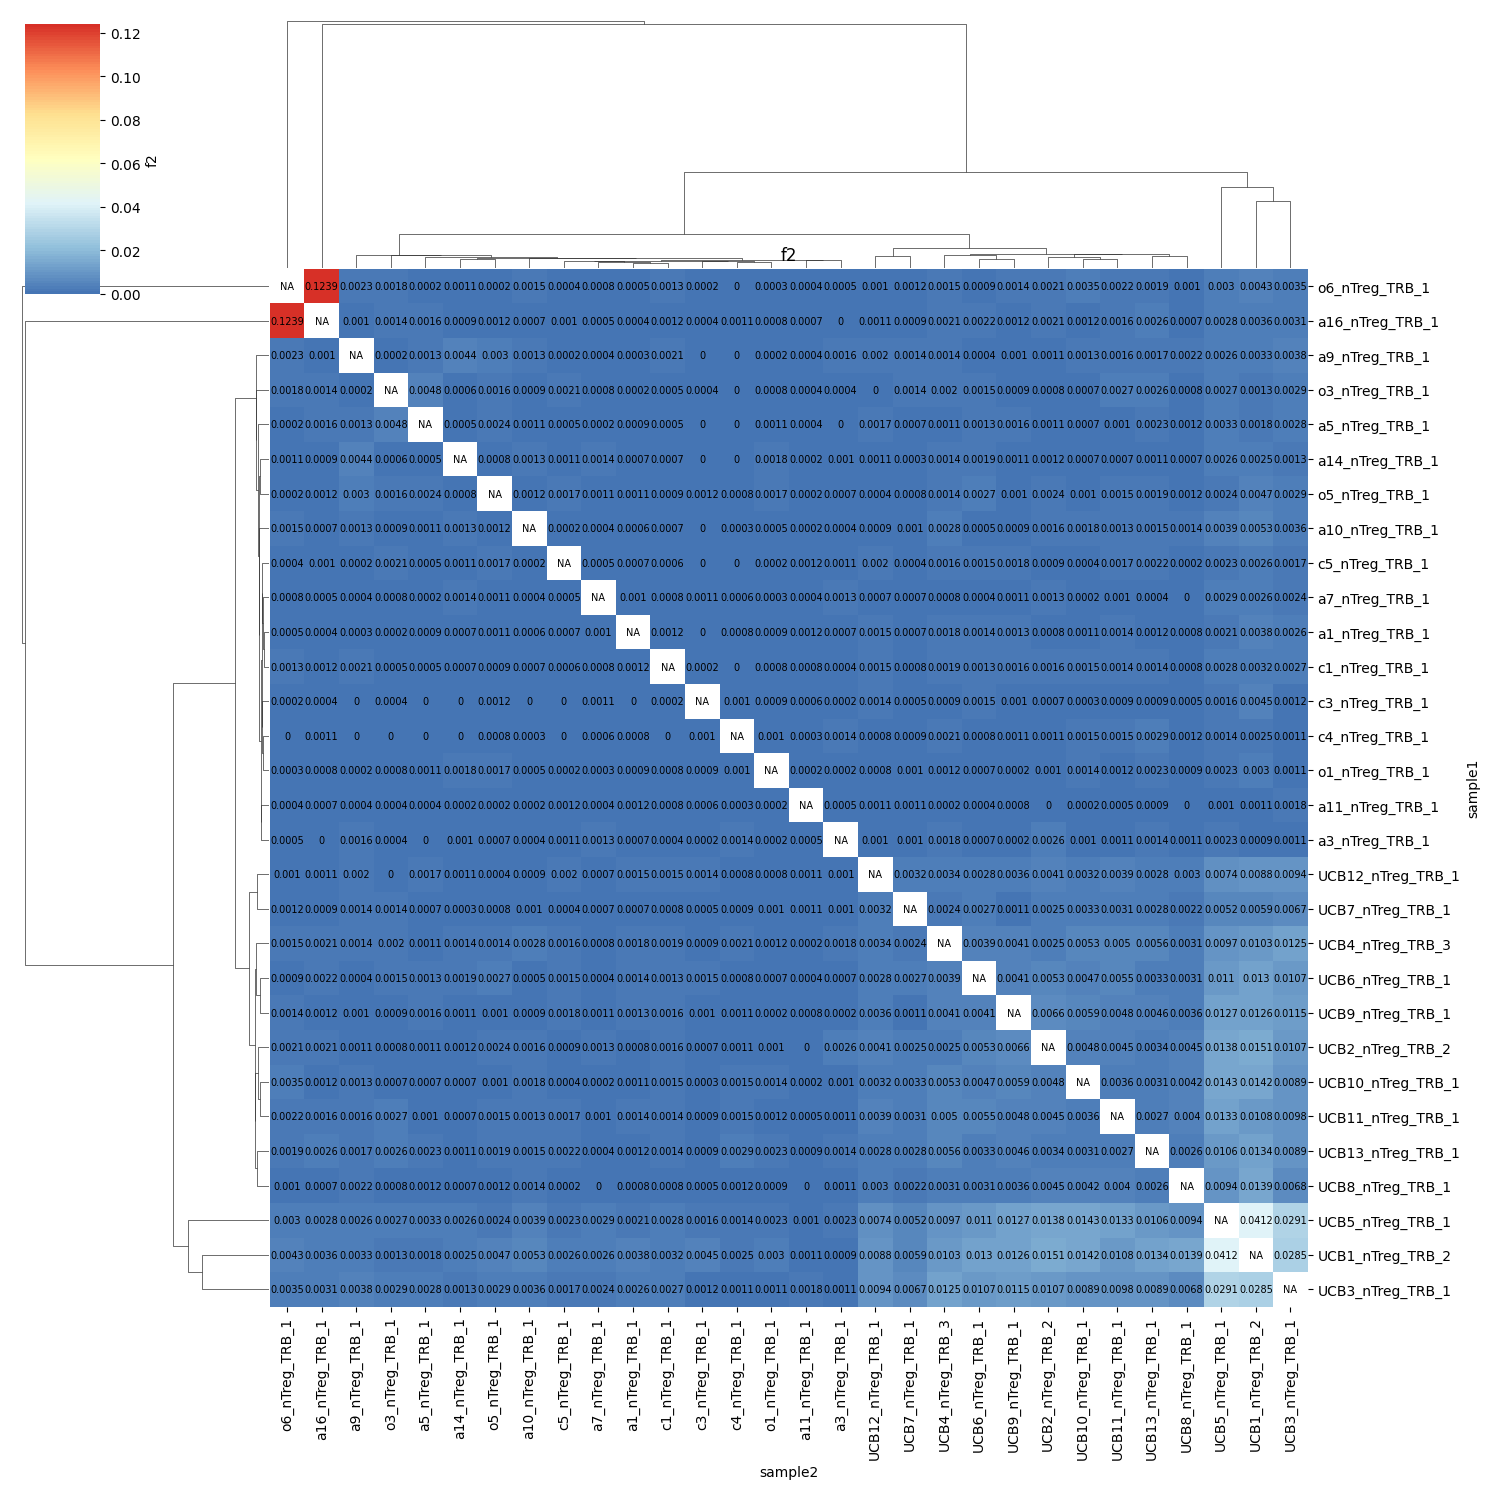

In [44]:
# Показываем тепловую карту F2, скрываем диагональ, кластеризуем образцы по сходству.
rsplot.beta_metric(beta_diversity,
                   metric="f2",
                   ignore_diagonal=True,
                   hclust=True,
                   log_values=False,
                   height = 15
                  )

**MDS (multidimensional scaling).** Это способ разместить образцы в двумерном пространстве так, чтобы **более близким** в смысле исходной матрицы расстояний объектам соответствовали более близкие точки. Мера F2 — *сходство*, поэтому для методов расстояний её преобразуют (например, в материалах семинара обсуждается $d_{ij}=-\log_{10}(F2_{ij}+\varepsilon)$ с малым $\varepsilon$). Конкретные внутренние вычисления определяет реализация `beta.mds`.

`MDS1` и `MDS2` — **условные координаты**, а не биологические параметры. `centroids=True` показывает центры групп, `dispersion=True` — разброс. Оцениваем, насколько образцы одной группы сближаются; не делаем вывод о значимости без отдельного статистического анализа.

### MDS for metric

In [45]:
# Преобразуем информацию о попарных отношениях между образцами в координаты MDS.
ucb_treg_mds = beta.mds(beta_diversity)
ucb_treg_mds

,sample_id,MDS1,MDS2
0,UCB10_nTreg_TRB_1,-0.274660,0.879502
1,UCB11_nTreg_TRB_1,-0.246230,0.134584
2,UCB12_nTreg_TRB_1,-0.418675,0.250050
3,UCB13_nTreg_TRB_1,-0.196530,0.069738
4,UCB1_nTreg_TRB_2,-0.311681,0.211097
5,UCB2_nTreg_TRB_2,-0.273790,1.088998
6,UCB3_nTreg_TRB_1,-0.036618,0.080675
7,UCB4_nTreg_TRB_3,-0.231223,0.354073
8,UCB5_nTreg_TRB_1,-0.121222,0.187183
9,UCB6_nTreg_TRB_1,-0.289855,0.171519


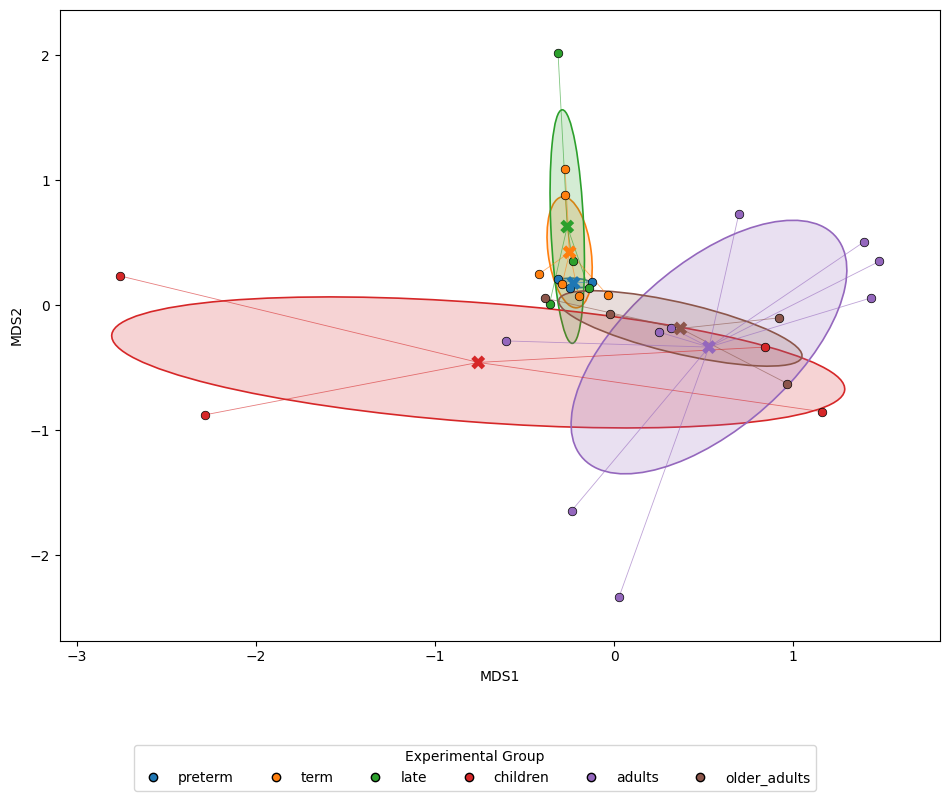

In [46]:
# Рисуем две координаты MDS с цветом групп, центрами и разбросом.
rsplot.beta_mds(ucb_treg_mds, metadata=metadata, group="experimental_group", centroids=True, dispersion=True, height=8)

**Кластеризация похожих CDR3.** Здесь **объекты — последовательности клонотипов**, а не образцы. Если две последовательности удовлетворяют правилу сходства, между ними можно провести ребро графа. `overlap_type='aaV'` использует аминокислотные CDR3 и V-ген, `mismatches=1` допускает одно несовпадение между сравниваемыми последовательностями.

Важная деталь: в связанном кластере две далёкие вершины могут отличаться **более чем на один символ**, поскольку соединяются цепочкой промежуточных вариантов. Такие кластеры — кандидаты для последующего поиска общей специфичности, но не прямое доказательство распознавания одного антигена. Расчёт и отрисовка могут быть тяжёлыми на больших данных.

## Clustering

### Create clusters

In [47]:
# Создаём пустой объект, в котором будут храниться клонотипы и связи между ними.
clusters = clustering.Clusters()
clusters

Clusters state:
  State: empty
Clonotypes: not read
Clusters: not created
Metadata: not added
Node Pgen: not calculated
ALICE: not calculated

In [48]:
# Загружаем отфильтрованные клонотипы всех выбранных образцов в объект кластеризации.
clusters.read_from_clonosets_df(clonosets_treg, cl_filter=downsample_filter)

Pooled 117361 clonotypes from 30 samples


In [49]:
# Соединяем близкие по CDR3aa клонотипы с одинаковым V-геном, допуская один mismatch.
clusters.create_clusters(overlap_type='aaV', mismatches=1)

Nodes list created: 117361 nodes
Using all available worker processes by default. Set cpu=1 or another integer to change this.
Find neighbour clonotypes |##################################################| 693/693 tasks processed
found 57007 edges
-----------------------------
NexworkX graph created
Found 7375 clusters (2 or more nodes) and 87113 single nodes. Total: 94488


In [50]:
# Добавляем к вершинам/последовательностям метаданные экспериментальных групп.
clusters.add_metadata(metadata)

In [51]:
# Преобразуем граф кластеризации в обычную таблицу для просмотра и фильтрации.
clusters_df = clusters.as_dataframe()
clusters_df

,cluster_no,node_id,cdr3aa,v,j,cdr3nt,sample_id,freq,count,isotype,n_neighbours,experimental_group,donor_id,subset,source
0,0,280,CASSVAIYNEQFF,TRBV5-1,TRBJ2-1,TGCGCCAGCAGCGTAGCTATCTACAATGAGCAGTTCTTC,a14_nTreg_TRB_1,0.000889,4,None,1,adults,a14,nTreg,PB
1,0,6371,CASSLGSYNEQFF,TRBV5-1,TRBJ2-1,TGCGCCAGCAGCTTGGGGTCATACAATGAGCAGTTCTTC,o1_nTreg_TRB_1,0.000444,2,None,23,older_adults,o1,nTreg,PB
2,0,16826,CASSFQGRDTQYF,TRBV5-1,TRBJ2-3,TGCGCCAGCAGCTTTCAGGGGAGAGATACGCAGTATTTT,a14_nTreg_TRB_1,0.000222,1,None,5,adults,a14,nTreg,PB
3,0,83244,CASSLGRNNEQFF,TRBV5-1,TRBJ2-1,TGCGCCAGCAGCTTGGGACGGAACAATGAGCAGTTCTTC,o6_nTreg_TRB_1,0.000222,1,None,6,older_adults,o6,nTreg,PB
4,0,91190,CASSLTGHYEQYF,TRBV5-1,TRBJ2-7,TGCGCCAGCAGCTTGACAGGGCACTACGAGCAGTACTTC,UCB3_nTreg_TRB_1,0.000222,1,None,15,term,UCB3,nTreg,UCB
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
117356,94483,35723,WRLGTEAFF,TRBV29-1,TRBJ1-1,TGGAGATTAGGGACTGAAGCTTTCTTT,UCB4_nTreg_TRB_3,0.000222,1,None,0,late,UCB4,nTreg,UCB
117357,94484,95685,WSAGQGAYEQYF,TRBV29-1,TRBJ2-7,TGGAGCGCAGGACAGGGGGCCTACGAGCAGTACTTC,UCB3_nTreg_TRB_1,0.000222,1,None,0,term,UCB3,nTreg,UCB
117358,94485,8348,WTTNTDTQYF,TRBV21-1,TRBJ2-3,TGGACAACGAACACAGATACGCAGTATTTT,UCB11_nTreg_TRB_1,0.000444,2,None,0,preterm,UCB11,nTreg,UCB
117359,94486,96028,YASSPDRGSYEQYF,TRBV18,TRBJ2-7,TATGCCAGCTCACCAGACAGGGGCTCCTACGAGCAGTACTTC,UCB3_nTreg_TRB_1,0.000222,1,None,0,term,UCB3,nTreg,UCB


In [52]:
# Считаем характеристики кластеров: число вершин, рёбер, размер и консенсус.
cluster_properties = clusters.properties()
cluster_properties

Using all available worker processes by default. Set cpu=1 or another integer to change this.


Calculating cluster properties |##################################################| 94488/94488 clusters processed


,cluster_no,cluster_id,nodes,edges,total_count,diameter,density,eccentricity,concensus_cdr3aa,concensus_cdr3nt,concensus_v,concensus_j
0,0,cluster_0,1012,4831,1217,24,0.009444,17.876482,CASSLGGTYEQYF,TGCGCCAGCAGCTTGGGGGGCGCCGATGAGCAGTACTTC,TRBV5-1,TRBJ2-7
1,1,cluster_1,773,5905,984,17,0.019790,12.610608,CASSLGGYEQYF,TGCGCCAGCAGCTTGGGCGCCGATGAGCAGTACTTC,TRBV5-1,TRBJ2-7
2,2,cluster_2,638,1758,775,29,0.008651,21.540752,CASSLGGGTDTQYF,TGCGCCAGCAGCTTGGGAGGGGGCACAGATACGCAGTACTTC,TRBV5-1,TRBJ2-3
3,3,cluster_3,320,1660,385,12,0.032524,8.796875,CASSLGGNYGYTF,TGCGCCAGCAGCTTGGAAGGGGACTATGGCTACACCTTC,TRBV5-1,TRBJ1-2
4,4,cluster_4,317,3584,401,15,0.071557,11.227129,CASSLGETQYF,TGCGCCAGCAGCTTGGCAGAGACGCAGTACTTC,TRBV5-1,TRBJ2-5
...,...,...,...,...,...,...,...,...,...,...,...,...
94483,94483,cluster_94483,1,0,1,0,0.000000,0.000000,WRLGTEAFF,TGGAGATTAGGGACTGAAGCTTTCTTT,TRBV29-1,TRBJ1-1
94484,94484,cluster_94484,1,0,1,0,0.000000,0.000000,WSAGQGAYEQYF,TGGAGCGCAGGACAGGGGGCCTACGAGCAGTACTTC,TRBV29-1,TRBJ2-7
94485,94485,cluster_94485,1,0,2,0,0.000000,0.000000,WTTNTDTQYF,TGGACAACGAACACAGATACGCAGTATTTT,TRBV21-1,TRBJ2-3
94486,94486,cluster_94486,1,0,1,0,0.000000,0.000000,YASSPDRGSYEQYF,TATGCCAGCTCACCAGACAGGGGCTCCTACGAGCAGTACTTC,TRBV18,TRBJ2-7


In [53]:
# Отбираем кластеры, исключая указанные V- и J-сегменты из демонстрации.
# # Поля concensus_v/concensus_j названы так в выводе библиотеки.
cluster_properties.query("concensus_v != 'TRBV5-1' and concensus_j not in ['TRBJ2-7', 'TRBJ2-3', 'TRBJ1-2']")

,cluster_no,cluster_id,nodes,edges,total_count,diameter,density,eccentricity,concensus_cdr3aa,concensus_cdr3nt,concensus_v,concensus_j
11,11,cluster_11,177,785,227,15,0.050398,11.485876,CASSLGDEQYF,TGTGCCAGCAGTTTAGGCGATGAGCAGTACTTC,TRBV12-3,TRBJ2-1
21,21,cluster_21,117,359,136,13,0.052903,9.111111,CSARGGSNQPQHF,TGCAGTGCTAGAGCGGGGAGCAATCAGCCCCAGCATTTT,TRBV20-1,TRBJ1-5
22,22,cluster_22,113,732,137,8,0.115676,5.991150,CSARQGNQPQHF,TGCAGTGCTAGAGAGGGCAATCAGCCCCAGCATTTT,TRBV20-1,TRBJ1-5
27,27,cluster_27,90,264,99,12,0.065918,8.722222,CASSLGGGNQPQHF,TGTGCCAGCAGTTTAGGAGGGGGCAATCAGCCCCAGCATTTT,TRBV12-3,TRBJ1-5
29,29,cluster_29,81,296,93,11,0.091358,7.802469,CASSPGGETQYF,TGTGCCAGCTCACCACGGGGAGAGACCCAGTACTTC,TRBV18,TRBJ2-5
...,...,...,...,...,...,...,...,...,...,...,...,...
94477,94477,cluster_94477,1,0,1,0,0.000000,0.000000,WASSLTGGVETQYF,TGGGCCAGCAGTTTGACAGGGGGGGTGGAGACCCAGTACTTC,TRBV6-5,TRBJ2-5
94479,94479,cluster_94479,1,0,1,0,0.000000,0.000000,WASTPGETQYF,TGGGCCAGCACCCCAGGAGAGACCCAGTACTTC,TRBV11-2,TRBJ2-5
94480,94480,cluster_94480,1,0,1,0,0.000000,0.000000,WGPKKGEIGELFF,TGGGGTCCCAAGAAAGGGGAAATCGGGGAGCTGTTTTTT,TRBV10-3,TRBJ2-2
94482,94482,cluster_94482,1,0,1,0,0.000000,0.000000,WQAQGQPQHF,TGGCAGGCTCAGGGGCAGCCCCAGCATTTT,TRBV23-1,TRBJ1-5


In [54]:
# Смотрим сводное представление объекта кластеров.
clusters

Clusters state:
  Completed: clonotypes read, clusters created, metadata added
Clonotypes:
    source: clonosets_df
    clonotypes: 117361
    samples: 30
    input_samples: 30
    filter:
      name: default_filter
      functionality: f
      downsample_size: 4500
      top: None
      by_umi: True
      mix_tails: False
      seed: 100
      count_threshold: None
      unweight: False
      recount_fractions: True
      white_list: []
      black_list: []
      pool_by: 
      convert: True
      ignore_small_clonosets: False
      retain_alleles: False
Graph: 117361 nodes and 57007 edges
Clusters: 7375 clusters (2 or more nodes) and 87113 single nodes. Total: 94488
Clustering parameters:
    method: mismatches
    overlap_type: aaV
    mismatches: 1
Metadata columns: experimental_group, donor_id, subset, source
Node Pgen: not calculated
ALICE: not calculated

**Визуализация графа.** Вершины представляют последовательности/клонотипы, ребра — заданное выше сходство. Цвет показывает экспериментальную группу; подписи и размеры связаны с числом наблюдений. Здесь выводятся кластеры с номерами от 20 до 29; сами номера — **идентификаторы по результату текущего расчёта**, а не универсальные биологические метки. При другом входном наборе или параметрах их состав может измениться.

### Plot clusters

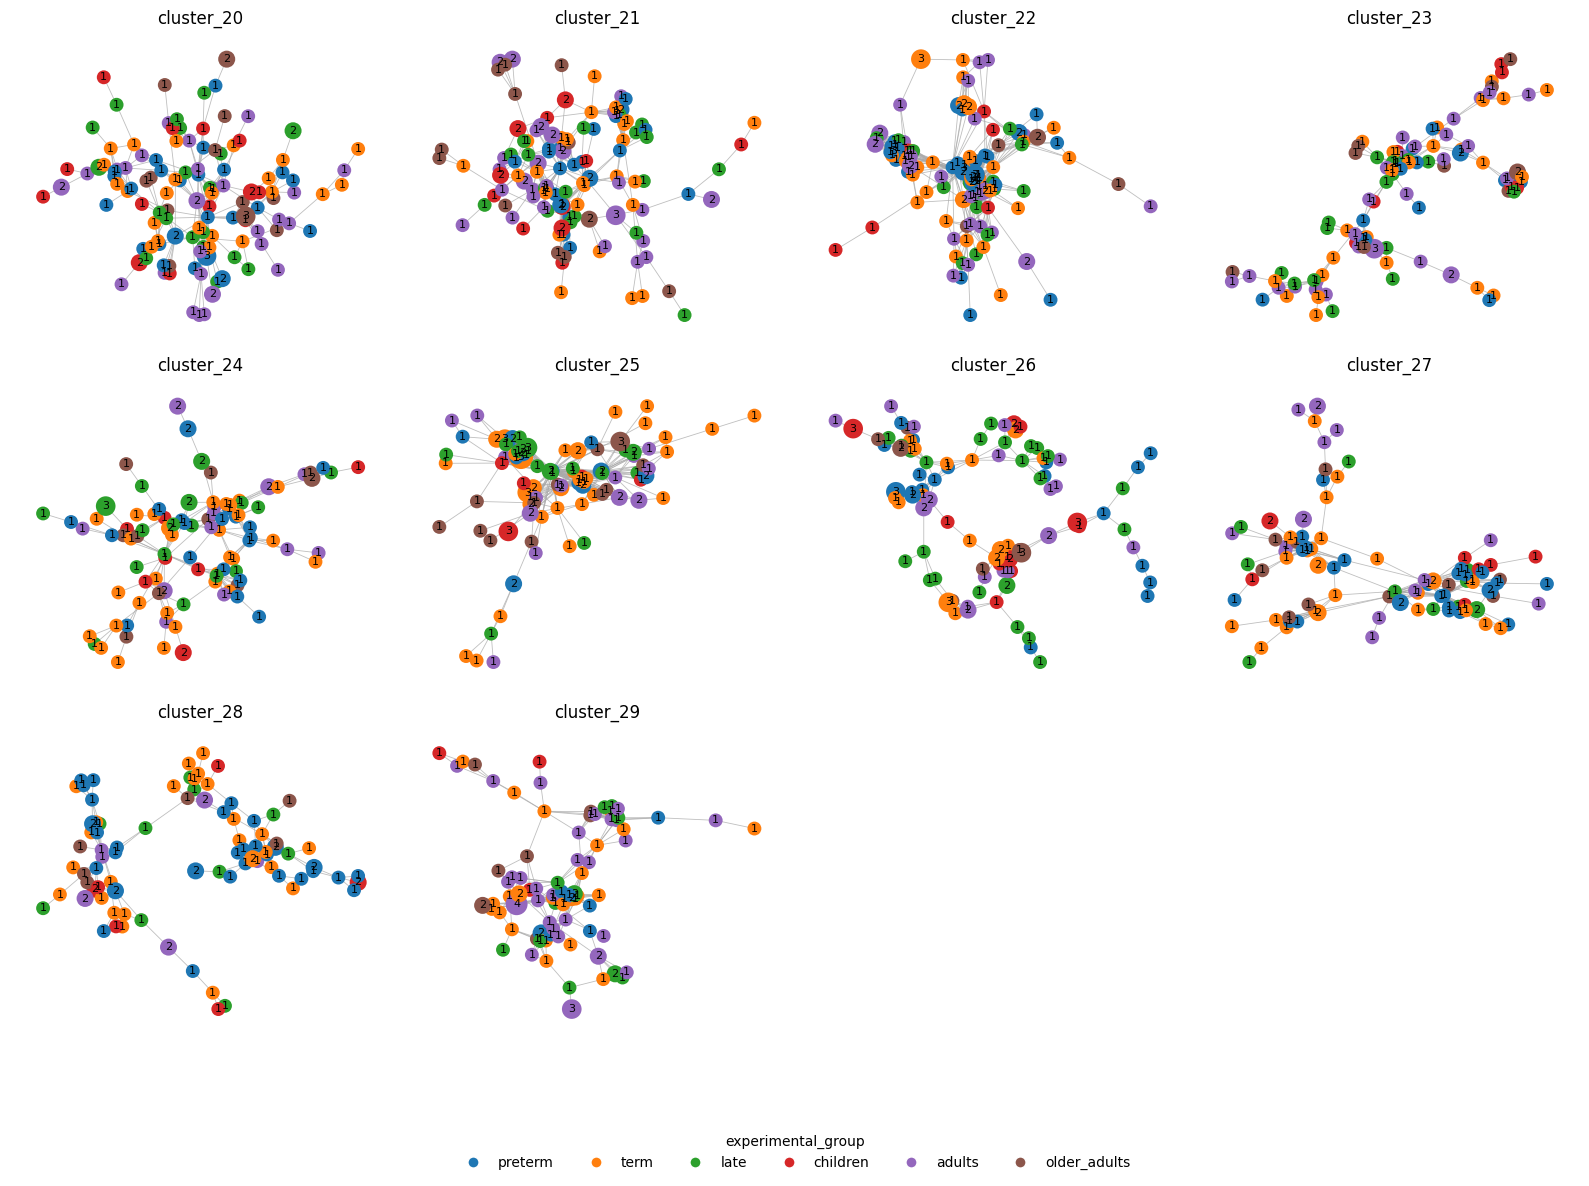

In [55]:
# Рисуем кластеры 20–29; цвет кодирует группу, размер узла — его count.
clusters.plot_cluster(range(20,30), color="experimental_group", label="count", log_scaled=False, size="count", linear_scale=50)

## Для самостоятельного анализа

В примере выше использовались `nTreg`. Для домашней работы выберите другую отсортированную популяцию (`nCD4` или `nCD8`), проверьте количество доступных образцов и их глубину по `clonoset_stats`, **обоснуйте собственное значение `downsample`** и повторите ключевые метрики. Затем измените один из параметров фильтрации и покажите, какие выводы устойчивы к выбору настроек.

В конце представьте **короткие биологические выводы**, а не только графики: какие группы сравниваются, что означает каждая ось, как интерпретировать изменение показателя и какие есть ограничения (глубина, выборка, различие популяций, случайность субсэмплирования).